# Predicting Depression from Health and Lifestyle (NHANES 2017–2018)

**NIT6160 Data Warehousing and Mining · Project: Health Dataset Analysis and Prediction**

One notebook, run top to bottom (Kernel → Restart & Run All):

| Part | Steps | What |
|---|---|---|
| A | 1–6 | Build the dataset from the 8 NHANES files and save `data/nhanes_clean.csv` |
| B | 7–12 | Explore and visualise the data (Tasks 3–4) |
| C | 13–14 | Split 80/20 and prepare the columns |
| D | 15–20 | Train, tune and compare three classifiers (Task 5) |
| E | 21 | Unsupervised learning: k-means clustering |

Raw files are in `data/raw/`. Outcome: `depressed` = PHQ-9 score ≥ 10.


## Setup

Needs Python with pandas, numpy, matplotlib and scikit-learn (Anaconda or Google Colab have them) and an internet connection the first time. The cell below downloads the 8 raw NHANES files (about 15 MB) from the CDC into `data/raw/`.


In [68]:
# Setup: get the 8 NHANES 2017-2018 files from the CDC (skipped if they are already in data/raw)
import os, urllib.request

BASE = 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/'
FILES = ['DEMO_J', 'DPQ_J', 'ALQ_J', 'BMX_J', 'MCQ_J', 'PAQ_J', 'SLQ_J', 'SMQ_J']

os.makedirs('data/raw', exist_ok=True)
for name in FILES:
    path = f'data/raw/{name}.xpt'
    if not os.path.exists(path):
        urllib.request.urlretrieve(BASE + name + '.xpt', path)
        print('downloaded', path)
print('raw files ready:', sorted(os.listdir('data/raw')))


raw files ready: ['ALQ_J.xpt', 'BMX_J.xpt', 'DEMO_J.xpt', 'DPQ_J.xpt', 'MCQ_J.xpt', 'PAQ_J.xpt', 'SLQ_J.xpt', 'SMQ_J.xpt']


# Part A: Build the dataset

Read the NHANES 2017–2018 files, score the PHQ-9, join the feature files, clean the survey codes and save one table with one row per adult.

## Step 1: Read the demographics file (DEMO_J)

In [69]:
import pandas as pd

In [70]:
demo = pd.read_sas('data/raw/DEMO_J.xpt', format='xport', encoding=None).round(4)

In [71]:
print(demo.shape)
print(demo.head())

(9254, 46)
      SEQN  SDDSRVYR  RIDSTATR  RIAGENDR  RIDAGEYR  RIDAGEMN  RIDRETH1  \
0  93703.0      10.0       2.0       2.0       2.0       NaN       5.0   
1  93704.0      10.0       2.0       1.0       2.0       NaN       3.0   
2  93705.0      10.0       2.0       2.0      66.0       NaN       4.0   
3  93706.0      10.0       2.0       1.0      18.0       NaN       5.0   
4  93707.0      10.0       2.0       1.0      13.0       NaN       5.0   

   RIDRETH3  RIDEXMON  RIDEXAGM  ...  DMDHREDZ  DMDHRMAZ  DMDHSEDZ  \
0       6.0       2.0      27.0  ...       3.0       1.0       3.0   
1       3.0       1.0      33.0  ...       3.0       1.0       2.0   
2       4.0       2.0       NaN  ...       1.0       2.0       NaN   
3       6.0       2.0     222.0  ...       3.0       1.0       2.0   
4       7.0       2.0     158.0  ...       2.0       1.0       3.0   

     WTINT2YR    WTMEC2YR  SDMVPSU  SDMVSTRA  INDHHIN2  INDFMIN2  INDFMPIR  
0   9246.4919   8539.7313      2.0     145.0  

In [72]:
demo['SEQN'].is_unique

True

## Step 2: PHQ-9 score and the outcome

The 9 PHQ-9 answers are scored 0–3 (7 = refused, 9 = don't know). Adults with any refused or missing answer are dropped, the answers are summed (0–27), and `depressed` = 1 when the score is 10 or more (the standard screening cut-off).

In [73]:
dpq = pd.read_sas('data/raw/DPQ_J.xpt', format='xport', encoding=None).round(4)

In [74]:
print(dpq.shape)

(5533, 11)


In [75]:
dpq['DPQ010'].value_counts(dropna=False).sort_index()

DPQ010
0.0    3792
1.0     816
2.0     280
3.0     198
7.0       4
9.0       4
NaN     439
Name: count, dtype: int64

In [76]:
items = [f'DPQ0{i}0' for i in range(1, 10)]

print(items)

['DPQ010', 'DPQ020', 'DPQ030', 'DPQ040', 'DPQ050', 'DPQ060', 'DPQ070', 'DPQ080', 'DPQ090']


In [77]:
dpq[items] = dpq[items].where(dpq[items] <= 3)
dpq = dpq.dropna(subset=items)
dpq['phq9_score'] = dpq[items].sum(axis=1)
dpq['depressed'] = (dpq['phq9_score'] >= 10).astype(int)
print(dpq.shape)
print(dpq['phq9_score'])
print(dpq['depressed'])
dpq['depressed'].value_counts()

(5068, 13)
0       0.0
1       0.0
2       0.0
4       2.0
5       1.0
       ... 
5528    0.0
5529    0.0
5530    3.0
5531    0.0
5532    7.0
Name: phq9_score, Length: 5068, dtype: float64
0       0
1       0
2       0
4       0
5       0
       ..
5528    0
5529    0
5530    0
5531    0
5532    0
Name: depressed, Length: 5068, dtype: int64


depressed
0    4609
1     459
Name: count, dtype: int64

## Step 3: Join the 7 feature files on SEQN

A left join keeps all 5,068 adults with a PHQ-9 score and adds 15 features from the other files. The row count is checked after every join.

In [78]:
df = dpq[['SEQN', 'phq9_score', 'depressed']]
demo_cols = ['RIDAGEYR', 'RIAGENDR', 'DMDEDUC2', 'DMDMARTL', 'INDFMPIR']
df = df.merge(demo[['SEQN'] + demo_cols], on='SEQN', how='left')
print(df.shape)
df.head()

(5068, 8)


,SEQN,phq9_score,depressed,RIDAGEYR,RIAGENDR,DMDEDUC2,DMDMARTL,INDFMPIR
0,93705.0,0.0,0,66.0,2.0,2.0,3.0,0.82
1,93706.0,0.0,0,18.0,1.0,NaN,NaN,NaN
2,93708.0,0.0,0,66.0,2.0,1.0,1.0,1.63
3,93711.0,2.0,0,56.0,1.0,5.0,1.0,5.00
4,93712.0,1.0,0,18.0,1.0,NaN,NaN,0.76


In [79]:
features = {
    'SLQ_J': ['SLD012', 'SLQ050'],
    'SMQ_J': ['SMQ020'],
    'ALQ_J': ['ALQ121'],
    'BMX_J': ['BMXBMI'],
    'PAQ_J': ['PAQ650', 'PAD680'],
    'MCQ_J': ['MCQ160C', 'MCQ220', 'MCQ080'],
}

In [80]:
for name, cols in features.items():
    table = pd.read_sas(f'data/raw/{name}.xpt', format='xport', encoding=None).round(4)
    df = df.merge(table[['SEQN'] + cols], on='SEQN', how='left')
    print(name, df.shape)

SLQ_J (5068, 10)
SMQ_J (5068, 11)
ALQ_J (5068, 12)
BMX_J (5068, 13)
PAQ_J (5068, 15)
MCQ_J (5068, 18)


Missing values per column after the joins:

In [81]:
df.isna().sum()

SEQN            0
phq9_score      0
depressed       0
RIDAGEYR        0
RIAGENDR        0
DMDEDUC2      243
DMDMARTL      243
INDFMPIR      630
SLD012         36
SLQ050          0
SMQ020          0
ALQ121        567
BMXBMI         58
PAQ650          0
PAD680          9
MCQ160C       243
MCQ220        243
MCQ080          0
dtype: int64

## Step 4: Survey codes → missing

NHANES stores "refused" and "don't know" as numbers (7/9, 77/99, 7777/9999). Left in, a model would read them as real answers, so they are set to missing. In the alcohol column 7 and 9 are real answers, so only 77/99 are codes there.

In [82]:
for col in ['DMDEDUC2', 'SLQ050', 'SMQ020', 'PAQ650', 'MCQ160C', 'MCQ220', 'MCQ080']:
    df[col] = df[col].where(~df[col].isin([7, 9]))
for col in ['DMDMARTL', 'ALQ121']:
    df[col] = df[col].where(~df[col].isin([77, 99]))
df['PAD680'] = df['PAD680'].where(df['PAD680'] < 7777)
df.isna().sum()

SEQN            0
phq9_score      0
depressed       0
RIDAGEYR        0
RIAGENDR        0
DMDEDUC2      249
DMDMARTL      248
INDFMPIR      630
SLD012         36
SLQ050          3
SMQ020          0
ALQ121        571
BMXBMI         58
PAQ650          0
PAD680         36
MCQ160C       258
MCQ220        244
MCQ080          3
dtype: int64

## Step 5: Readable names and labels

CDC codes are replaced with names and words, e.g. `RIAGENDR` 1/2 → `sex` Male/Female. Measurements stay as numbers. Alcohol frequency is simplified to `drank_past_year` Yes/No.

In [83]:
yes_no = {1: 'Yes', 2: 'No'}
clean = pd.DataFrame({
    'id': df['SEQN'].astype(int),
    'age': df['RIDAGEYR'],
    'sex': df['RIAGENDR'].map({1: 'Male', 2: 'Female'}),
    'education': df['DMDEDUC2'].map({1: 'Less than 9th grade', 2: '9–11th grade', 3: 'High school',
                                     4: 'Some college', 5: 'College graduate'}),
    'marital_status': df['DMDMARTL'].map({1: 'Married', 2: 'Widowed', 3: 'Divorced', 4: 'Separated',
                                          5: 'Never married', 6: 'Living with partner'}),
    'income_ratio': df['INDFMPIR'],
    'sleep_hours': df['SLD012'],
    'sleep_trouble': df['SLQ050'].map(yes_no),
    'smoked_100': df['SMQ020'].map(yes_no),
    'drank_past_year': df['ALQ121'].map(lambda v: v if pd.isna(v) else ('No' if v == 0 else 'Yes')),
    'bmi': df['BMXBMI'],
    'vigorous_activity': df['PAQ650'].map(yes_no),
    'sitting_minutes': df['PAD680'],
    'heart_disease': df['MCQ160C'].map(yes_no),
    'cancer_ever': df['MCQ220'].map(yes_no),
    'told_overweight': df['MCQ080'].map(yes_no),
    'phq9_score': df['phq9_score'].astype(int),
    'depressed': df['depressed'],
})
print(clean.shape)

(5068, 18)


In [84]:
clean.head()

,id,age,sex,education,marital_status,income_ratio,sleep_hours,sleep_trouble,smoked_100,drank_past_year,bmi,vigorous_activity,sitting_minutes,heart_disease,cancer_ever,told_overweight,phq9_score,depressed
0,93705,66.0,Female,9–11th grade,Divorced,0.82,8.0,No,Yes,Yes,31.7,No,300.0,No,No,No,0,0
1,93706,18.0,Male,NaN,NaN,NaN,10.5,No,No,NaN,21.5,No,240.0,NaN,NaN,No,0,0
2,93708,66.0,Female,Less than 9th grade,Married,1.63,8.0,No,No,NaN,23.7,No,120.0,No,No,No,0,0
3,93711,56.0,Male,College graduate,Married,5.00,7.0,Yes,No,Yes,21.3,Yes,420.0,No,No,No,2,0
4,93712,18.0,Male,NaN,NaN,0.76,7.5,No,Yes,No,19.7,Yes,120.0,NaN,NaN,No,1,0


**Result:** 5,068 adults × 18 columns. Education and marital status are missing for 18–19-year-olds because NHANES only asks them from age 20.

## Step 6: Save the clean table

In [85]:
clean.to_csv('data/nhanes_clean.csv', index=False)

check = pd.read_csv('data/nhanes_clean.csv')
print(check.shape)
check.head()

(5068, 18)


,id,age,sex,education,marital_status,income_ratio,sleep_hours,sleep_trouble,smoked_100,drank_past_year,bmi,vigorous_activity,sitting_minutes,heart_disease,cancer_ever,told_overweight,phq9_score,depressed
0,93705,66.0,Female,9–11th grade,Divorced,0.82,8.0,No,Yes,Yes,31.7,No,300.0,No,No,No,0,0
1,93706,18.0,Male,NaN,NaN,NaN,10.5,No,No,NaN,21.5,No,240.0,NaN,NaN,No,0,0
2,93708,66.0,Female,Less than 9th grade,Married,1.63,8.0,No,No,NaN,23.7,No,120.0,No,No,No,0,0
3,93711,56.0,Male,College graduate,Married,5.00,7.0,Yes,No,Yes,21.3,Yes,420.0,No,No,No,2,0
4,93712,18.0,Male,NaN,NaN,0.76,7.5,No,Yes,No,19.7,Yes,120.0,NaN,NaN,No,1,0


# Part B: Explore the data (Tasks 3–4)

Part B starts from the clean table saved in Part A.

In [86]:
import matplotlib.pyplot as plt

In [87]:
import pandas as pd

## Step 7: Structure and variable types

5 numeric columns, 10 categorical columns, an ID and the outcome. The type decides which statistics, charts and pre-processing each column gets.

In [88]:
df = pd.read_csv('data/nhanes_clean.csv')

numeric = ['age', 'income_ratio', 'sleep_hours', 'bmi', 'sitting_minutes']
categories = ['sex', 'education', 'marital_status', 'sleep_trouble', 'smoked_100', 'drank_past_year',
                'vigorous_activity', 'heart_disease', 'cancer_ever', 'told_overweight']

pd.DataFrame({'type': df.dtypes, 'distinct values': df.nunique()})

,type,distinct values
id,int64,5068
age,float64,63
sex,str,2
education,str,5
marital_status,str,6
income_ratio,float64,429
sleep_hours,float64,24
sleep_trouble,str,2
smoked_100,str,2
drank_past_year,str,2


## Step 8: Missing-data patterns

### 8a: Count and percent missing per column

In [89]:
missing = df.isna().sum().to_frame('missing')
missing['percent'] = (100 * missing['missing'] / len(df)).round(1)
missing = missing[missing['missing'] > 0].sort_values('missing', ascending=False)
missing

,missing,percent
income_ratio,630,12.4
drank_past_year,571,11.3
heart_disease,258,5.1
education,249,4.9
marital_status,248,4.9
cancer_ever,244,4.8
bmi,58,1.1
sleep_hours,36,0.7
sitting_minutes,36,0.7
sleep_trouble,3,0.1


**Finding:** the most missing is income at **12.4%**, so no column needs to be dropped.

### 8b: Is the missing data random?

In [90]:
young = df['age'] < 20
print('Missing education, age 18–19:', df.loc[young, 'education'].isna().sum(), 'of', young.sum())
print('Missing education, age 20+  :', df.loc[~young, 'education'].isna().sum(), 'of', (~young).sum())

Missing education, age 18–19: 243 of 243
Missing education, age 20+  : 6 of 4825


In [91]:
df.groupby(df['income_ratio'].isna())['depressed'].mean() * 100

income_ratio
False     8.832808
True     10.634921
Name: depressed, dtype: float64

**Finding:** education is missing for the 18–19-year-olds (not asked under 20), and adults with missing income are more often depressed (10.6% vs 8.8%), so the gaps are not random and should be filled, not dropped.

## Step 9: Centre and spread

Mean, median, mode, standard deviation, variance, IQR and skew for each numeric column.

### 9a: Quick summary

In [92]:
df[numeric].describe().round(2)

,age,income_ratio,sleep_hours,bmi,sitting_minutes
count,5068.00,4438.00,5032.00,5010.00,5032.00
mean,49.57,2.55,7.60,29.78,332.27
std,18.46,1.61,1.65,7.45,199.11
min,18.00,0.00,2.00,14.80,0.00
25%,33.00,1.18,6.50,24.62,180.00
50%,51.00,2.13,7.50,28.50,300.00
75%,64.00,4.08,8.50,33.60,480.00
max,80.00,5.00,14.00,86.20,1320.00


### 9b: Full statistics table

In [93]:
cols = numeric + ['phq9_score']
stats = pd.DataFrame({
    'mean': df[cols].mean(),
    'median': df[cols].median(),
    'mode': df[cols].mode().iloc[0],
    'variance': df[cols].var(),
    'std': df[cols].std(),
    'min': df[cols].min(),
    'max': df[cols].max(),
    'IQR': df[cols].quantile(0.75) - df[cols].quantile(0.25),
    'skew': df[cols].skew(),
}).round(2)

stats

,mean,median,mode,variance,std,min,max,IQR,skew
age,49.57,51.00,80.0,340.95,18.46,18.0,80.0,31.00,-0.06
income_ratio,2.55,2.13,5.0,2.60,1.61,0.0,5.0,2.90,0.33
sleep_hours,7.60,7.50,8.0,2.71,1.65,2.0,14.0,2.00,-0.03
bmi,29.78,28.50,27.9,55.49,7.45,14.8,86.2,8.98,1.26
sitting_minutes,332.27,300.00,240.0,39646.46,199.11,0.0,1320.0,300.00,0.88
phq9_score,3.24,2.00,0.0,18.02,4.24,0.0,25.0,5.00,1.90


**Findings:**

| Column | Finding |
|---|---|
| Age | Balanced (skew ≈ 0). Mode 80 because 80 means "80 or older". |
| Income ratio | Capped at 5 ("5 or more"), so 5 is also the most common value. |
| Sleep | 7.6 hours on average; extremes of 2 and 14 hours are checked in Step 10. |
| BMI | Mean 29.8 (overweight range), right-skewed by a few very high values (max 86). |
| Sitting | About 5.5 hours a day on average, with a wide spread. |
| PHQ-9 score | Median 2, mode 0, skew 1.90: most adults have few symptoms, so only about 9% score 10 or more. |

BMI, sitting time and the PHQ-9 score are skewed, so the median and IQR are reported alongside the mean and SD.

## Step 10: Outliers (IQR rule)

A value is an outlier if it is more than 1.5 × IQR below Q1 or above Q3. Example: the BMI fences are 11.2 and 47.1.

In [94]:
q1 = df[numeric].quantile(0.25)
q3 = df[numeric].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

In [95]:
outliers = pd.DataFrame({
    'lower fence': low,
    'upper fence': high,
    'outliers': ((df[numeric] < low) | (df[numeric] > high)).sum(),
}).round(1)

In [96]:
outliers['percent'] = (100 * outliers['outliers'] / len(df)).round(1)
outliers

,lower fence,upper fence,outliers,percent
age,-13.5,110.5,0,0.0
income_ratio,-3.2,8.4,0,0.0
sleep_hours,3.5,11.5,120,2.4
bmi,11.2,47.1,141,2.8
sitting_minutes,-270.0,930.0,42,0.8


**Findings:**

| Column | Outliers |
|---|---|
| Age, income | None. Both are capped (at 80 and 5). A negative fence just means "nothing can be that low". |
| Sleep | 120 people sleep under 3.5 h or over 11.5 h. |
| BMI | 141 people are above 47.1 (severe obesity). |
| Sitting | 42 people sit more than 15.5 h a day. |

**Decision: keep them.** They are plausible real people, not typos. Scaling (Part C) stops them dominating logistic regression and SVM; random forest is not affected by extreme values.

### Summary of Steps 8–10

- **Missing data:** at most 12%. It isn't random: education is missing for the 18–19-year-olds, and missing income is linked to more depression.
- **Shape:** BMI, sitting time and the PHQ-9 score are right-skewed, so the median and IQR describe them better than the mean.
- **Outliers:** 2–3% on sleep and BMI. They're real values, so we keep them.

## Step 11: Depression rate by group

The percentage depressed in each group, compared with the overall rate of **9.1%**.

### 11a: One feature, sleep trouble

In [97]:
t = df.groupby('sleep_trouble')['depressed'].agg(['mean', 'size'])
t['mean'] = (t['mean'] * 100).round(1)
t

,mean,size
sleep_trouble,,
No,4.6,3642
Yes,20.5,1423


### 11b: Cut numbers into bands (`pd.cut`) to compare groups

In [98]:
df['age_group'] = pd.cut(df['age'], bins=[17, 29, 44, 59, 80], labels=['18–29', '30–44', '45–59', '60–80'])
df['income_group'] = pd.cut(df['income_ratio'], bins=[-1, 1, 2, 4, 5],
                             labels=['Below poverty line', '1–2×', '2–4×', '4× or more'])
df[['age', 'age_group', 'income_ratio', 'income_group']].head()

,age,age_group,income_ratio,income_group
0,66.0,60–80,0.82,Below poverty line
1,18.0,18–29,NaN,NaN
2,66.0,60–80,1.63,1–2×
3,56.0,45–59,5.00,4× or more
4,18.0,18–29,0.76,Below poverty line


### 11c: Rates by sex, age, income, marital status, heart disease and activity

In [99]:
  for g in ['sex', 'age_group', 'income_group', 'marital_status', 'heart_disease', 'vigorous_activity']:
      t = df.groupby(g, observed=True)['depressed'].agg(['mean', 'size'])
      t['mean'] = (t['mean'] * 100).round(1)
      print(t, '\n')


        mean  size
sex               
Female  10.7  2590
Male     7.3  2478 

           mean  size
age_group            
18–29       8.1   963
30–44       9.2  1104
45–59       9.6  1179
60–80       9.1  1822 

                    mean  size
income_group                  
Below poverty line  14.0   869
1–2×                10.4  1225
2–4×                 7.3  1201
4× or more           4.7  1143 

                     mean  size
marital_status                 
Divorced             14.6   556
Living with partner   9.3   450
Married               6.1  2405
Never married        10.5   870
Separated            15.1   179
Widowed              13.6   360 

               mean  size
heart_disease            
No              8.7  4590
Yes            15.0   220 

                   mean  size
vigorous_activity            
No                 10.5  3792
Yes                 4.6  1276 



### How the exploration shapes the models

- Only **9.1%** are depressed → judge models on recall and F1 (not accuracy), use a stratified split and class balancing.
- Missing data is at most 12% and not random → fill the gaps instead of dropping a quarter of the adults.
- BMI, sitting and PHQ-9 are skewed → fill missing numbers with the median.
- Outliers are real people → keep them; scaling stops them dominating.
- Sleep trouble, income, marital status, activity and sex show the biggest rate gaps → the models' most important features should agree.

## Step 12: Charts (Task 4)

### 12a: Histograms of all numeric columns and the PHQ-9 score

Red line = the PHQ-9 cut-off of 10. The PHQ-9 score is only described, never used as a model input, because the outcome is made from it.

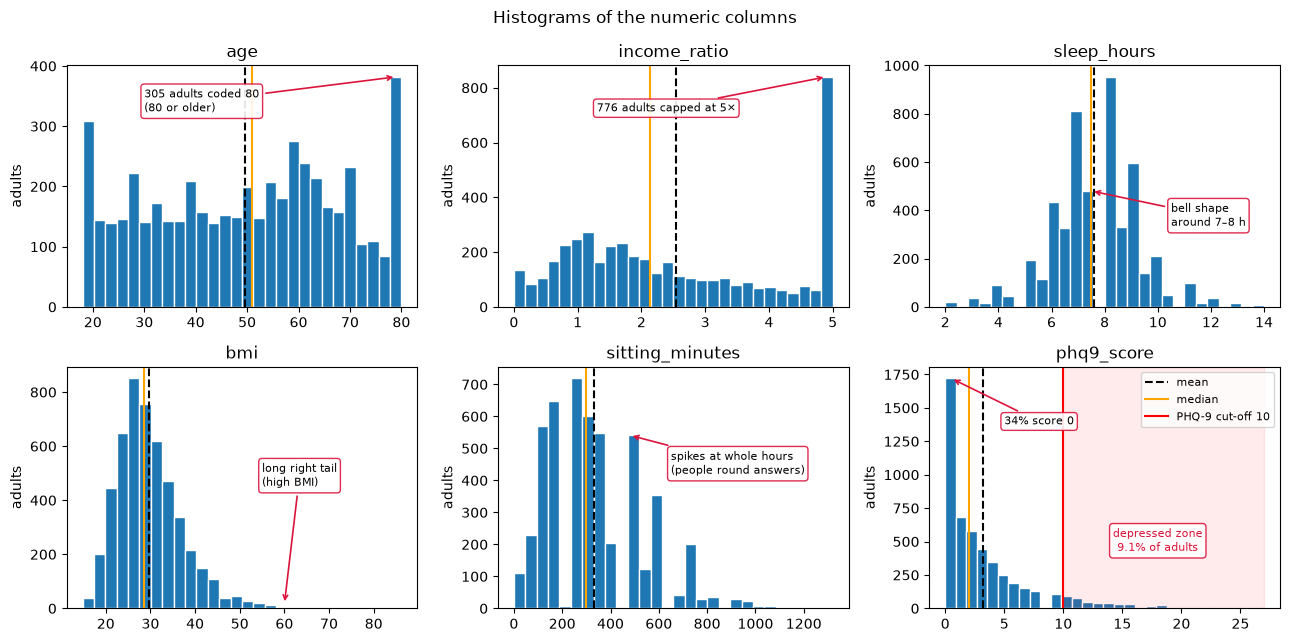

In [100]:
import numpy as np

# styles for the marks, reused by the later charts: an arrow and a white label box
arrow = dict(arrowstyle='->', color='crimson', lw=1.2)
note = dict(boxstyle='round', facecolor='white', edgecolor='crimson', alpha=0.9)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
hist = {}                                           # bar heights of each histogram, used by the marks
for ax, col in zip(axes.flat, numeric + ['phq9_score']):
    hist[col] = ax.hist(df[col].dropna(), bins=28, edgecolor='white')
    ax.axvline(df[col].mean(), color='black', linestyle='--', label='mean')
    ax.axvline(df[col].median(), color='orange', label='median')
    ax.set_title(col)
    ax.set_ylabel('adults')

# height of the bar that holds value x in column col
def height(col, x):
    n, edges, _ = hist[col]
    return n[min(np.searchsorted(edges, x, side='right') - 1, len(n) - 1)]

age_ax, inc_ax, sleep_ax, bmi_ax, sit_ax, phq_ax = axes.flat

# marks: what each histogram shows
n80 = (df['age'] == 80).sum()
age_ax.annotate(f'{n80} adults coded 80\n(80 or older)', xy=(79, height('age', 80)), xytext=(30, height('age', 80) * 0.85),
                arrowprops=arrow, bbox=note, fontsize=8)
n5 = (df['income_ratio'] == 5).sum()
inc_ax.annotate(f'{n5} adults capped at 5×', xy=(4.9, height('income_ratio', 5)), xytext=(1.3, height('income_ratio', 5) * 0.85),
                arrowprops=arrow, bbox=note, fontsize=8)
sleep_ax.annotate('bell shape\naround 7–8 h', xy=(7.5, height('sleep_hours', 7.5)), xytext=(10.5, height('sleep_hours', 7.5) * 0.7),
                  arrowprops=arrow, bbox=note, fontsize=8)
bmi_ax.annotate('long right tail\n(high BMI)', xy=(60, height('bmi', 60) + 10), xytext=(55, height('bmi', 28) * 0.6),
                arrowprops=arrow, bbox=note, fontsize=8)
sit_ax.annotate('spikes at whole hours\n(people round answers)', xy=(480, height('sitting_minutes', 480)), xytext=(650, height('sitting_minutes', 300) * 0.7),
                arrowprops=arrow, bbox=note, fontsize=8)

# PHQ-9: shade the depressed zone (10 or more) and mark the people who scored 0
phq_ax.axvline(10, color='red', label='PHQ-9 cut-off 10')
phq_ax.axvspan(10, 27, color='red', alpha=0.08)
phq_ax.text(18, height('phq9_score', 0) * 0.25, f"depressed zone\n{df['depressed'].mean() * 100:.1f}% of adults",
            ha='center', fontsize=8, color='crimson', bbox=note)
zero = (df['phq9_score'] == 0).mean() * 100
phq_ax.annotate(f'{zero:.0f}% score 0', xy=(0.5, height('phq9_score', 0)), xytext=(5, height('phq9_score', 0) * 0.8),
                arrowprops=arrow, bbox=note, fontsize=8)
phq_ax.legend(fontsize=8, loc='upper right')

plt.suptitle('Histograms of the numeric columns')
plt.tight_layout()
plt.show()

**Findings:**

| Chart | What it shows |
|---|---|
| Age | Spread fairly evenly from 18 to 80; the tall bar at 80 is everyone aged 80 or over. |
| Income ratio | About half of families are between 0.5 and 3 times the poverty line; the tall bar at 5 is everyone at 5× or more. |
| Sleep | Most adults sleep 6–9 hours, peaking at 7–8. |
| BMI | Peak at 25–30 with a tail to the right. |
| Sitting | Usually 2–8 hours a day; spikes at round hours (self-reported). |
| PHQ-9 score | The tallest bar is 0 (about a third of adults); only the small tail past 10 (9%) counts as depressed. |

### 12b: Box plots, not depressed vs depressed

Box = middle 50%, orange line = median, circles = outliers. A box sitting higher or lower means the two groups differ on that measure.

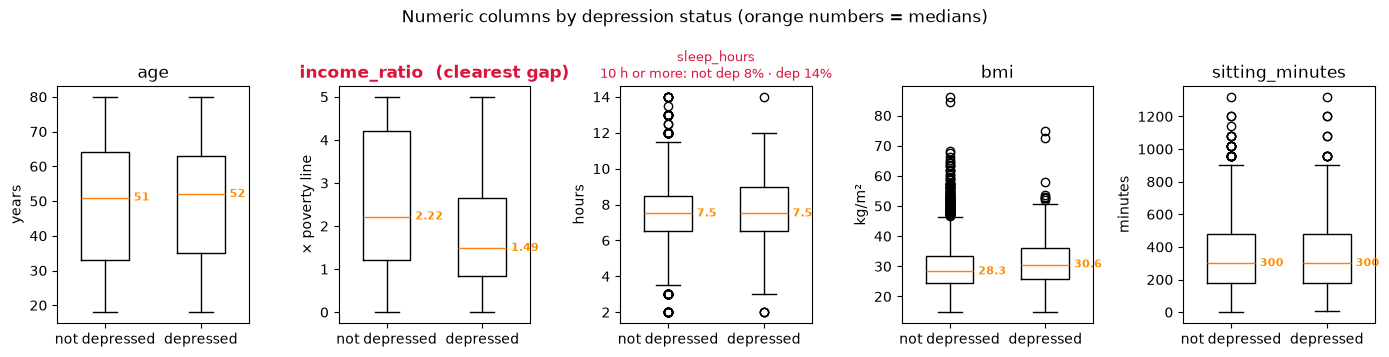

In [101]:
units = {'age': 'years', 'income_ratio': '× poverty line', 'sleep_hours': 'hours',
         'bmi': 'kg/m²', 'sitting_minutes': 'minutes'}
fig, axes = plt.subplots(1, 5, figsize=(14, 3.6))
for ax, col in zip(axes, numeric):
    not_dep = df.loc[df['depressed'] == 0, col].dropna()
    dep = df.loc[df['depressed'] == 1, col].dropna()
    ax.boxplot([not_dep, dep], widths=0.5)
    ax.set_xticks([1, 2], ['not depressed', 'depressed'])
    ax.set_title(col)
    ax.set_ylabel(units[col])

    # mark: write each median next to its box
    for x, values in [(1, not_dep), (2, dep)]:
        ax.text(x + 0.3, values.median(), f'{values.median():g}', va='center', fontsize=8,
                color='darkorange', fontweight='bold')

    # mark: the long sleepers (10 hours or more) in each group
    if col == 'sleep_hours':
        long_not, long_dep = (not_dep >= 10).mean() * 100, (dep >= 10).mean() * 100
        ax.set_title(f'sleep_hours\n10 h or more: not dep {long_not:.0f}% · dep {long_dep:.0f}%', fontsize=9, color='crimson')

# mark: the clearest difference
axes[1].set_title('income_ratio  (clearest gap)', color='crimson', fontweight='bold')
plt.suptitle('Numeric columns by depression status (orange numbers = medians)')
plt.tight_layout()
plt.show()

**Findings:**

| Measure | Median (not depressed → depressed) | Reading |
|---|---|---|
| Age | 51 → 52 | almost no difference |
| Income ratio | 2.2 → **1.5** | the clearest difference: lower income |
| Sleep | 7.5 → 7.5 | same median, more long sleepers among the depressed |
| BMI | 28.3 → **30.6** | slightly higher |
| Sitting | 300 → 300 min | no clear difference |

The boxes overlap on every measure, so no single measurement can identify depression; the models must combine many features.

### 12c: Depression rate by group (bar charts)

Bar = % depressed in that group. Red dashed line = overall rate of 9.1%.

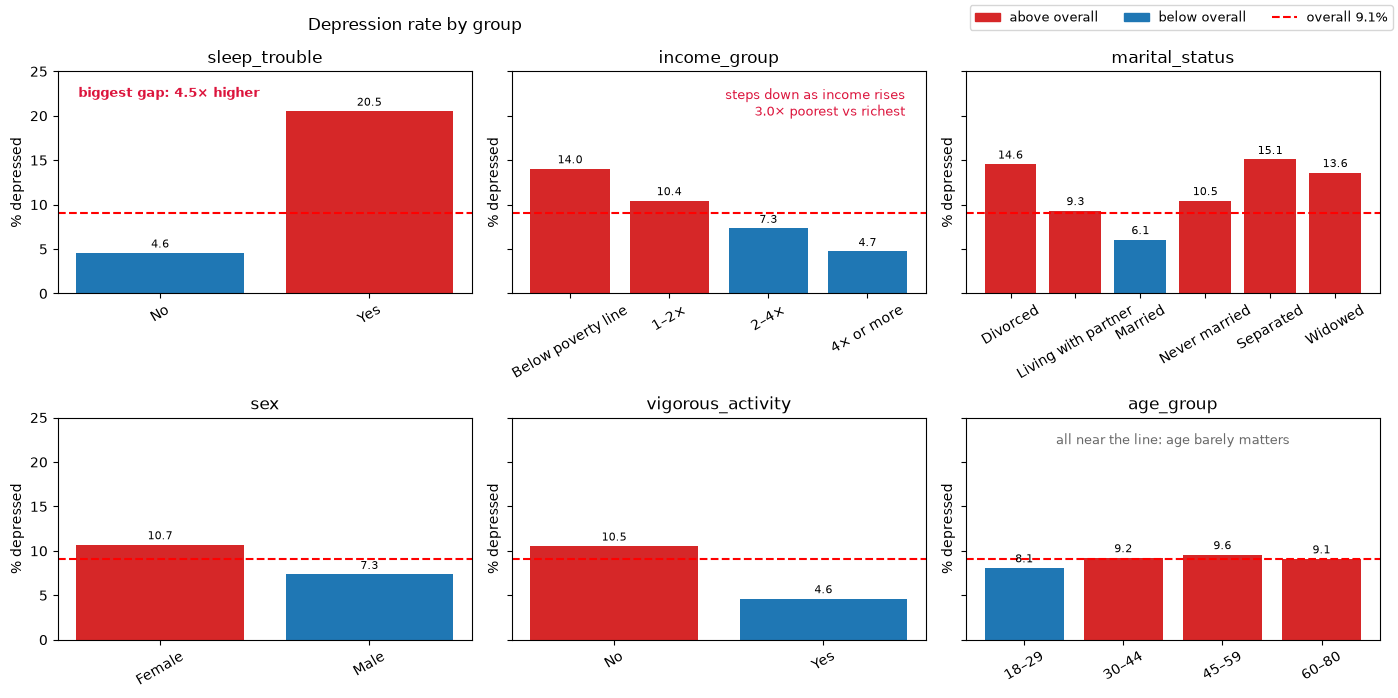

In [102]:
# patches for the legend (coloured squares)
from matplotlib.patches import Patch

# the 6 columns to chart, one small chart each
groups = ['sleep_trouble', 'income_group', 'marital_status', 'sex', 'vigorous_activity', 'age_group']

# overall depression rate: mean of a 0/1 column = share of 1s → 9.06%
overall = df['depressed'].mean() * 100

# a grid of 2 rows × 3 charts; sharey=True = all charts use the same y scale
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)

# one pass per chart: ax = the small chart, g = the column name
for ax, g in zip(axes.flat, groups):
    # Step 11's sum: % depressed per group (index = group names, values = percentages)
    rate = df.groupby(g, observed=True)['depressed'].mean() * 100

    # mark: red bar = above the overall rate, blue = below; the % on top of every bar
    bars = ax.bar(rate.index.astype(str), rate.values, color=['tab:red' if v > overall else 'tab:blue' for v in rate.values])
    ax.bar_label(bars, fmt='%.1f', fontsize=8, padding=2)

    # horizontal red dashed line at the overall rate
    ax.axhline(overall, color='red', linestyle='--')
    ax.set_title(g)                            # chart title = column name
    ax.set_ylabel('% depressed')               # y axis label
    ax.set_ylim(0, 25)                         # room for the labels on top
    ax.tick_params(axis='x', rotation=30)      # tilt x labels so long names don't overlap

# mark: the biggest gap (sleep trouble) and the flat one (age)
st = df.groupby('sleep_trouble')['depressed'].mean() * 100
axes.flat[0].text(0.05, 0.93, f'biggest gap: {st["Yes"] / st["No"]:.1f}× higher', transform=axes.flat[0].transAxes,
                  fontsize=9, color='crimson', fontweight='bold', va='top')
inc = df.groupby('income_group', observed=True)['depressed'].mean() * 100
axes.flat[1].text(0.95, 0.93, f'steps down as income rises\n{inc.iloc[0] / inc.iloc[-1]:.1f}× poorest vs richest',
                  transform=axes.flat[1].transAxes, fontsize=9, color='crimson', ha='right', va='top')
axes.flat[5].text(0.5, 0.93, 'all near the line: age barely matters', transform=axes.flat[5].transAxes,
                  fontsize=9, color='dimgray', ha='center', va='top')

# one legend for the whole figure
fig.legend(handles=[Patch(color='tab:red', label='above overall'), Patch(color='tab:blue', label='below overall'),
                    plt.Line2D([], [], color='red', ls='--', label=f'overall {overall:.1f}%')],
           loc='upper right', ncol=3, fontsize=9)
plt.suptitle('Depression rate by group', x=0.3)
plt.tight_layout()
plt.show()

**Findings:** sleep trouble 20.5% vs 4.6% (4.5×); income steps down 14.0 → 10.4 → 7.3 → 4.7% (3.0× poorest vs richest); separated 15.1%, divorced 14.6% and widowed 13.6% vs married 6.1%; women 10.7% vs men 7.3%; no vigorous activity 10.5% vs 4.6%; the age groups are all 8.1–9.6%, near the overall rate.

### 12d: Correlation matrix (heatmap)

Pearson r between each pair of numeric columns and the PHQ-9 score, from −1 to +1 (below 0.1 none, 0.1–0.3 weak, 0.3–0.5 moderate).

income_ratio      -0.18
age               -0.02
sleep_hours       -0.02
sitting_minutes    0.05
bmi                0.10
Name: phq9_score, dtype: float64


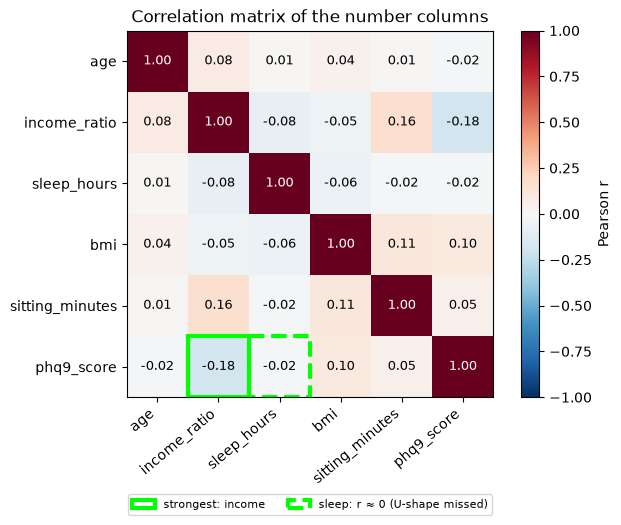

In [103]:
  # Pearson r for every pair of number columns, plus the PHQ-9 score
  corr = df[numeric + ['phq9_score']].corr().round(2)

  # how each number column moves with the PHQ-9 score, smallest to largest
  print(corr['phq9_score'].drop('phq9_score').sort_values())

  # draw the 6 x 6 table as a heatmap: red = positive, blue = negative, white = none
  fig, ax = plt.subplots(figsize=(7, 5.5))
  im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)

  # column names on both axes
  ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha='right')
  ax.set_yticks(range(len(corr)), corr.columns)

  # write r in every square (white text on the dark diagonal)
  for i in range(len(corr)):
      for j in range(len(corr)):
          r = corr.iloc[i, j]
          ax.text(j, i, f'{r:.2f}', ha='center', va='center', fontsize=9, color='white' if abs(r) > 0.6 else 'black')

  # marks: solid box = strongest link with PHQ-9 (income), dashed box = sleep (r ≈ 0 despite the U-shape)
  from matplotlib.patches import Rectangle
  cols = list(corr.columns)
  for col, style, label in [('income_ratio', '-', 'strongest: income'), ('sleep_hours', '--', 'sleep: r ≈ 0 (U-shape missed)')]:
      i, j = cols.index('phq9_score'), cols.index(col)
      ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor='lime', lw=3, ls=style, label=label))
  ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2, fontsize=8)

  # the colour key and title
  fig.colorbar(im, ax=ax, label='Pearson r')
  ax.set_title('Correlation matrix of the number columns')
  plt.tight_layout()
  plt.show()

**Finding:** income has the strongest link with the PHQ-9 score (r = −0.18). No two features are strongly correlated with each other (max 0.16), so none is redundant.

### 12e: Scatter plots: income and BMI against the PHQ-9 score

A small random jitter is added so stacked points are visible.

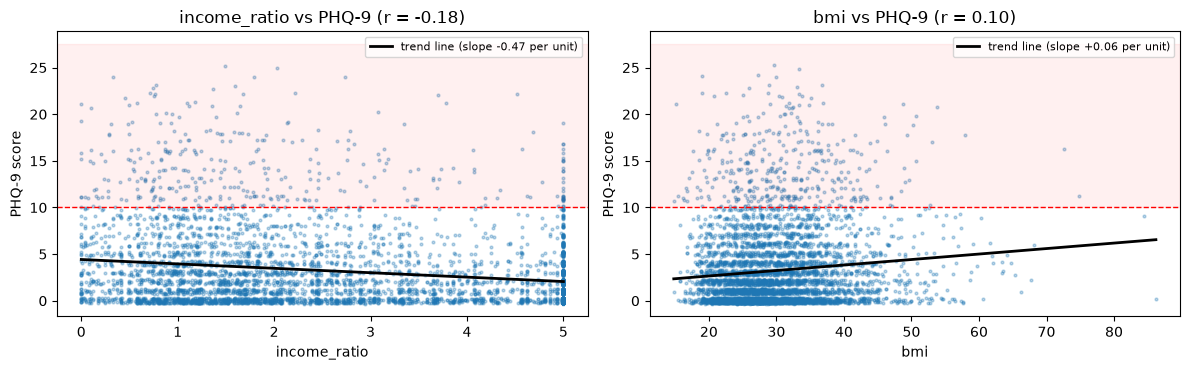

In [104]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, c in zip(ax, ['income_ratio', 'bmi']):
    a.scatter(df[c], df['phq9_score'] + rng.uniform(-0.3, 0.3, len(df)), s=4, alpha=0.3)
    a.axhline(10, color='red', ls='--', lw=1)
    a.axhspan(10, 27.5, color='red', alpha=0.06)              # mark: the depressed zone

    # mark: straight trend line through the cloud (np.polyfit = best straight line)
    d = df[[c, 'phq9_score']].dropna()
    slope, intercept = np.polyfit(d[c], d['phq9_score'], 1)
    xs = np.linspace(d[c].min(), d[c].max(), 50)
    a.plot(xs, slope * xs + intercept, color='black', lw=2, label=f'trend line (slope {slope:+.2f} per unit)')
    a.legend(fontsize=8, loc='upper right')

    a.set_xlabel(c); a.set_ylabel('PHQ-9 score')
    a.set_title(f"{c} vs PHQ-9 (r = {corr.loc[c, 'phq9_score']:.2f})")
plt.tight_layout(); plt.show()

**Finding:** both clouds are wide, with only weak tilts: lower income and higher BMI go with slightly higher scores. About a third of adults score 0.

### 12f: Line graphs: depression rate by age and by hours of sleep

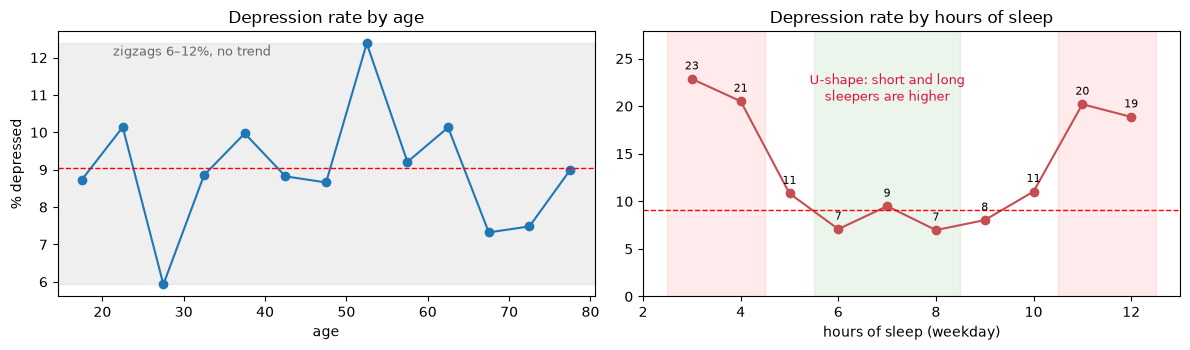

In [105]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))

# age: cut into 5-year bands, % depressed in each band, plotted at the band's middle
by_age = df.groupby(pd.cut(df['age'], range(15, 85, 5)), observed=True)['depressed'].mean() * 100
ax[0].plot([b.mid for b in by_age.index], by_age.values, 'o-'); ax[0].set_xlabel('age'); ax[0].set_ylabel('% depressed')
ax[0].set_title('Depression rate by age')
# mark: the band the line stays inside, and the overall rate
ax[0].axhspan(by_age.min(), by_age.max(), color='gray', alpha=0.12)
ax[0].axhline(overall, color='red', ls='--', lw=1)
ax[0].text(0.25, 0.95, f'zigzags {by_age.min():.0f}–{by_age.max():.0f}%, no trend', transform=ax[0].transAxes,
           ha='center', va='top', fontsize=9, color='dimgray')

# sleep: keep 3-12 hours, round to whole hours, % depressed at each hour
sleep = df[df['sleep_hours'].between(3, 12)]
by_sleep = sleep.groupby(sleep['sleep_hours'].round())['depressed'].mean() * 100
ax[1].plot(by_sleep.index, by_sleep.values, 'o-', color='#C44E52'); ax[1].set_xlabel('hours of sleep (weekday)')
ax[1].set_title('Depression rate by hours of sleep')
# marks: the value on every point, the two high ends (red) and the low middle (green)
for x, y in by_sleep.items():
    ax[1].text(x, y + 1, f'{y:.0f}', ha='center', fontsize=8)
ax[1].axvspan(2.5, 4.5, color='red', alpha=0.08)
ax[1].axvspan(10.5, 12.5, color='red', alpha=0.08)
ax[1].axvspan(5.5, 8.5, color='green', alpha=0.08)
ax[1].axhline(overall, color='red', ls='--', lw=1)
ax[1].text(7, by_sleep.max() * 0.9, 'U-shape: short and long\nsleepers are higher', ha='center', fontsize=9, color='crimson')
ax[1].set_ylim(0, by_sleep.max() + 5)
plt.tight_layout(); plt.show()

**Finding:** no clear trend with age. Sleep shows a U-shape: about 7–10% depressed for 6–9 hours, rising to about 20% at 3–4 hours and at 11–12 hours.

### 12g: Depression rate by education, smoking, heart disease and alcohol

Heart disease (from Step 11, not charted in 12c) plus three columns not compared yet: education, smoking and alcohol. Same reading as 12c: bar = % depressed, red dashed line = overall 9.1%.

education {'Less than 9th grade': 12.9, '9–11th grade': 12.6, 'High school': 9.7, 'Some college': 9.8, 'College graduate': 4.4} | adults: {'Some college': 1574, 'College graduate': 1174, 'High school': 1168, '9–11th grade': 523, 'Less than 9th grade': 380}
smoked_100 {'No': 6.8, 'Yes': 12.3} | adults: {'No': 2990, 'Yes': 2078}
heart_disease {'No': 8.7, 'Yes': 15.0} | adults: {'No': 4590, 'Yes': 220}
drank_past_year {'No': 11.6, 'Yes': 8.9} | adults: {'Yes': 3475, 'No': 1022}


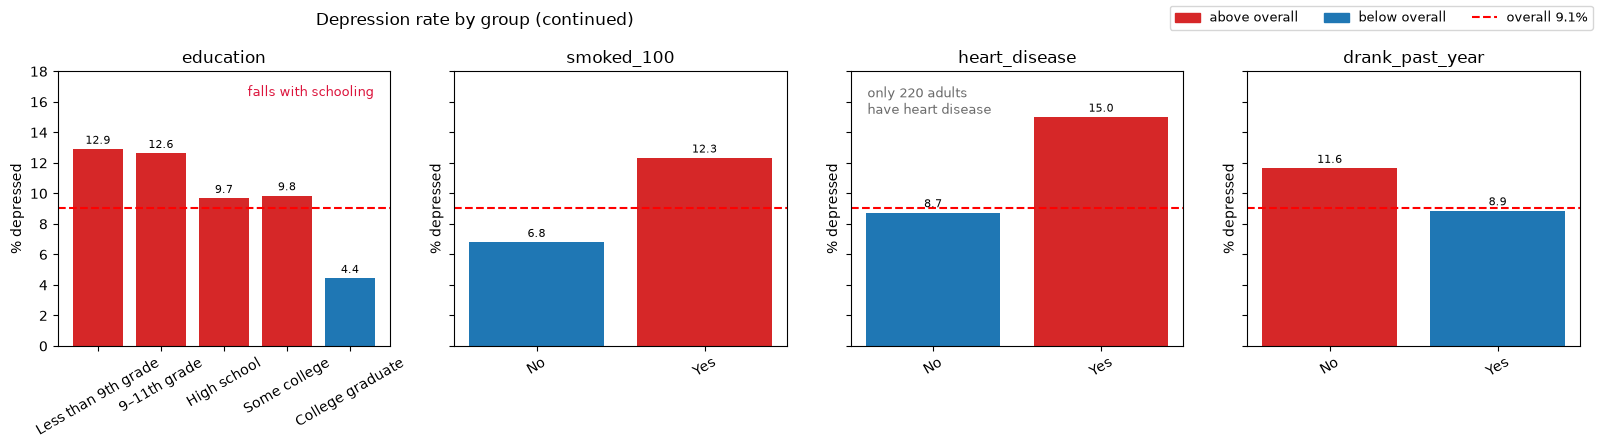

In [106]:
# 4 more columns, one small chart each
more = ['education', 'smoked_100', 'heart_disease', 'drank_past_year']

# put education in its natural order (otherwise it is alphabetical)
order = {'education': ['Less than 9th grade', '9–11th grade', 'High school', 'Some college', 'College graduate']}

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), sharey=True)
for ax, g in zip(axes, more):
    rate = df.groupby(g)['depressed'].mean() * 100          # % depressed per group (Step 11)
    if g in order:
        rate = rate.reindex(order[g])

    # mark: red bar = above the overall rate, blue = below; the % on top of every bar
    bars = ax.bar(rate.index.astype(str), rate.values, color=['tab:red' if v > overall else 'tab:blue' for v in rate.values])
    ax.bar_label(bars, fmt='%.1f', fontsize=8, padding=2)

    ax.axhline(overall, color='red', linestyle='--')
    ax.set_title(g)
    ax.set_ylabel('% depressed')
    ax.set_ylim(0, 18)
    ax.tick_params(axis='x', rotation=30)
    print(g, rate.round(1).to_dict(), '| adults:', df[g].value_counts().to_dict())

# mark: the clearest steps
axes[0].text(0.95, 0.95, 'falls with schooling', transform=axes[0].transAxes, ha='right', va='top', fontsize=9, color='crimson')
axes[2].text(0.05, 0.95, 'only 220 adults\nhave heart disease', transform=axes[2].transAxes, va='top', fontsize=9, color='dimgray')

fig.legend(handles=[Patch(color='tab:red', label='above overall'), Patch(color='tab:blue', label='below overall'),
                    plt.Line2D([], [], color='red', ls='--', label=f'overall {overall:.1f}%')],
           loc='upper right', ncol=3, fontsize=9)
plt.suptitle('Depression rate by group (continued)', x=0.3)
plt.tight_layout()
plt.show()

**Findings:**

| Chart | Bars (% depressed) | Reading |
|---|---|---|
| Education | 12.9 · 12.6 · 9.7 · 9.8 · **4.4** | steps down with schooling; college graduates under half the overall rate |
| Smoked 100+ | No 6.8 · Yes **12.3** | smokers 1.8× non-smokers |
| Heart disease | No 8.7 · Yes **15.0** | higher, but only 220 adults have it |
| Drank past year | No **11.6** · Yes 8.9 | non-drinkers slightly higher; may include people who stopped drinking because of illness, so a weak link |


# Part C: Prepare the data

## Step 13: Train/test split (80/20)

20% of adults are kept aside, unseen, to test the final models. The model learns only from the other 80%.

In [107]:
  # scikit-learn's function that splits data into train and test parts
  from sklearn.model_selection import train_test_split

In [108]:
  # X = the inputs (15 features), y = the answer we want to predict
  X = df[numeric + categories]
  y = df['depressed']

In [109]:
  # 80% train / 20% test; stratify=y keeps 9.1% depressed in both parts
  # shuffle the people, then cut X and y the same way into 80% train / 20% test
  # X, y             = what to split (inputs and answers, 5,068 rows each)
  # test_size=0.2    = 20% goes to the test set -> 1,014 people; 4,054 train
  # random_state=42  = the same shuffle every run, so results are repeatable
  # stratify=y       = both parts keep 9.1% depressed (367 of 4,054 and 92 of 1,014)
  # returns 4 parts, ALWAYS in this order: X_train, X_test, y_train, y_test
  #   X_train = inputs the model studies     y_train = their answers (the answer sheet)
  #   X_test  = inputs it guesses for later  y_test  = their answers (the marking key, never shown to the model)
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [110]:
  print('all  ', X.shape, '| depressed', y.sum())
  print('train', X_train.shape, '| depressed', y_train.sum(), f'({y_train.mean()*100:.1f}%)')
  print('test ', X_test.shape, '| depressed', y_test.sum(), f'({y_test.mean()*100:.1f}%)')

all   (5068, 15) | depressed 459
train (4054, 15) | depressed 367 (9.1%)
test  (1014, 15) | depressed 92 (9.1%)


**Result:** `stratify=y` keeps 9.1% depressed in both sets: 367 of 4,054 in training and 92 of 1,014 in test.

## Step 14: Fill gaps, one-hot encode, scale

| Problem | Numeric columns (5) | Categorical columns (10) |
|---|---|---|
| Gaps | fill with the training **median** (skewed data) | fill with the **most common answer** |
| Words | — | **one-hot encode**: one 0/1 column per answer |
| Different scales | **standardise**: (value − mean) ÷ SD | — |

Logistic regression and SVM need scaled inputs; random forest does not, but is not harmed.

### 14a: Build the pre-processing pipeline (`ColumnTransformer`)

In [111]:
  # tools from scikit-learn
  from sklearn.compose import ColumnTransformer       # different steps for different columns
  from sklearn.pipeline import Pipeline               # run steps one after another
  from sklearn.impute import SimpleImputer            # fill gaps
  from sklearn.preprocessing import StandardScaler, OneHotEncoder   # scale numbers / text -> 0/1 columns

In [112]:
  # for the 5 numeric columns: 1) fill gaps with the median, 2) scale
  num_steps = Pipeline([('impute', SimpleImputer(strategy='median')),
                        ('scale', StandardScaler())])

In [113]:
  # for the 10 categorical columns: 1) fill gaps with the most frequent answer, 2) one 0/1 column per answer
  cat_steps = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                        ('onehot', OneHotEncoder(handle_unknown='ignore'))])

In [114]:
  # send each list of columns to its own steps
  prep = ColumnTransformer([('num', num_steps, numeric),
                            ('cat', cat_steps, categories)])
  prep                    

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

### 14b: Fit on the training set only, then transform both sets

Medians, most common answers, means and SDs are learned from the training set only, so no information leaks from the test set.

In [115]:
  # fit = LEARN medians, most frequent answers, means and stds from X_train; transform = APPLY them
  X_train_ready = prep.fit_transform(X_train)

In [116]:
  # only transform: use what was learned from X_train (no peeking at the test set)
  X_test_ready = prep.transform(X_test)

In [117]:
  print('train', X_train.shape, '->', X_train_ready.shape)
  print('test ', X_test.shape, '->', X_test_ready.shape)

train (4054, 15) -> (4054, 32)
test  (1014, 15) -> (1014, 32)


**15 columns become 32:** the 5 numeric columns stay 5; the 10 categorical columns become 27 (sex 2 + education 5 + marital status 6 + 7 yes/no questions × 2 = 27).

In [118]:
  # the 32 new column names
  print(list(prep.get_feature_names_out()))

['num__age', 'num__income_ratio', 'num__sleep_hours', 'num__bmi', 'num__sitting_minutes', 'cat__sex_Female', 'cat__sex_Male', 'cat__education_9–11th grade', 'cat__education_College graduate', 'cat__education_High school', 'cat__education_Less than 9th grade', 'cat__education_Some college', 'cat__marital_status_Divorced', 'cat__marital_status_Living with partner', 'cat__marital_status_Married', 'cat__marital_status_Never married', 'cat__marital_status_Separated', 'cat__marital_status_Widowed', 'cat__sleep_trouble_No', 'cat__sleep_trouble_Yes', 'cat__smoked_100_No', 'cat__smoked_100_Yes', 'cat__drank_past_year_No', 'cat__drank_past_year_Yes', 'cat__vigorous_activity_No', 'cat__vigorous_activity_Yes', 'cat__heart_disease_No', 'cat__heart_disease_Yes', 'cat__cancer_ever_No', 'cat__cancer_ever_Yes', 'cat__told_overweight_No', 'cat__told_overweight_Yes']


### 14c: Before and after, for two training rows

Row 4369 has no gaps. Row 244 has income missing: it is filled with the training median (2.13) and then scaled.

In [119]:
  # put the 32 numbers back into a table with column names and the same row numbers as X_train
  after = pd.DataFrame(X_train_ready, columns=prep.get_feature_names_out(), index=X_train.index)

  # before: the original values of rows 4369 (no gaps) and 244 (income missing)
  display(X_train.loc[[4369, 244], ['age', 'income_ratio', 'sex', 'sleep_trouble']])

  # after: the same two people, filled, scaled and one-hot encoded
  display(after.loc[[4369, 244], ['num__age', 'num__income_ratio', 'cat__sex_Female', 'cat__sex_Male',
                                  'cat__sleep_trouble_No', 'cat__sleep_trouble_Yes']].round(2))

,age,income_ratio,sex,sleep_trouble
4369,58.0,5.0,Male,Yes
244,33.0,NaN,Male,No


,num__age,num__income_ratio,cat__sex_Female,cat__sex_Male,cat__sleep_trouble_No,cat__sleep_trouble_Yes
4369,0.46,1.65,0.0,1.0,0.0,1.0
244,-0.89,-0.24,0.0,1.0,1.0,0.0


# Part D: Train and evaluate the classifiers (Task 5)

The test set is used only for the final evaluation, never for training or choosing settings.

## Step 15: First model: logistic regression, plain vs balanced

In [120]:
  # the classifier and two ways to score it
  from sklearn.linear_model import LogisticRegression
  from sklearn.metrics import confusion_matrix, f1_score

  # 15a: plain model, no balancing
  lr_plain = LogisticRegression(max_iter=2000)   # max_iter = allow enough learning rounds to finish
  lr_plain.fit(X_train_ready, y_train)           # LEARN from the 4,054 training people + their answers


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [121]:
guess_plain = lr_plain.predict(X_test_ready)   # GUESS 0 or 1 for the 1,014 test people
print('plain    found', (guess_plain[y_test == 1] == 1).sum(), 'of', (y_test == 1).sum(), '| F1', round(f1_score(y_test, guess_plain), 3))

# Table 8 row: accuracy, ROC-AUC and the 2x2 table of the plain model
from sklearn.metrics import roc_auc_score
print('plain    accuracy', round((guess_plain == y_test).mean(), 3), '| ROC-AUC', round(roc_auc_score(y_test, lr_plain.predict_proba(X_test_ready)[:, 1]), 3))
print(confusion_matrix(y_test, guess_plain))   # rows = truth [not, depressed], columns = guess

plain    found 0 of 92 | F1 0.0
plain    accuracy 0.907 | ROC-AUC 0.757
[[920   2]
 [ 92   0]]


**Result:** the plain model is about 91% accurate but finds **0 of the 92** depressed adults, because 91% of adults are not depressed.

`class_weight='balanced'` makes each depressed adult count about 10× more during training (weight 5.52 vs 0.55), so the model can no longer ignore the rare class.

In [122]:
  # 15b: same model with class_weight='balanced'
  lr_bal = LogisticRegression(class_weight='balanced', max_iter=2000)   # missing a depressed person costs ~10x more
  lr_bal.fit(X_train_ready, y_train)
  guess_bal = lr_bal.predict(X_test_ready)
  print('balanced found', (guess_bal[y_test == 1] == 1).sum(), 'of', (y_test == 1).sum(), '| F1', round(f1_score(y_test, guess_bal), 3))

  # rows = truth (0, 1), columns = guess (0, 1)
  confusion_matrix(y_test, guess_bal)


balanced found 63 of 92 | F1 0.321


array([[684, 238],
       [ 29,  63]])

**Result:** the balanced model finds far more depressed adults, at the cost of more false alarms. For screening, a missed case is worse than a follow-up check.

## Step 16: Accuracy, recall, precision and F1

In [123]:


  # the 4 cells of the 2x2 table, by name (ravel = flatten [[TN, FP], [FN, TP]] into one row)
  tn, fp, fn, tp = confusion_matrix(y_test, guess_bal).ravel()
  print('TN', tn, '| FP', fp, '| FN', fn, '| TP', tp)

TN 684 | FP 238 | FN 29 | TP 63


In [124]:
  # the same scores by hand
  accuracy  = (tp + tn) / (tp + tn + fp + fn)       # all right guesses / everyone
  recall    = tp / (tp + fn)                        # found / all truly depressed
  precision = tp / (tp + fp)                        # truly depressed / all flagged
  f1        = 2 * precision * recall / (precision + recall)   # balance of the two
  print(f'accuracy {accuracy:.3f} | recall {recall:.3f} | precision {precision:.3f} | F1 {f1:.3f}')

accuracy 0.737 | recall 0.685 | precision 0.209 | F1 0.321


 F1 is the harmonic mean of precision and recall. It's high only when both are high.

In [125]:
  # a ready-made report of all the scores, per class
  from sklearn.metrics import classification_report
  # digits=3 = three decimals; class 1 (depressed) is the row that matters
  print(classification_report(y_test, guess_bal, digits=3))

              precision    recall  f1-score   support

           0      0.959     0.742     0.837       922
           1      0.209     0.685     0.321        92

    accuracy                          0.737      1014
   macro avg      0.584     0.713     0.579      1014
weighted avg      0.891     0.737     0.790      1014



**Note:** these scores are the untuned balanced model (C = 1). The tuned model in Step 18 scores accuracy 0.741, recall 0.685 and F1 0.324 on the same test set.

## Step 17: Tune the three models

Each model's settings are chosen with **GridSearchCV**: every combination is scored by F1 using 5-fold stratified cross-validation on the training set only, and the best is re-trained on all 4,054 training adults.

### 17a: Logistic regression (C)

Small C = simpler model; large C = closer fit to the training data.

In [126]:
  # tools for tuning: fold splitter, grid search, and pipeline (prep + model as one unit)
  from sklearn.model_selection import StratifiedKFold, GridSearchCV
  from sklearn.pipeline import Pipeline

In [127]:
# prep from Step 14 + the balanced model from Step 15, joined into one pipeline
lr_pipe = Pipeline([('prep', prep),
  ('model', LogisticRegression(class_weight='balanced', max_iter=2000))])

In [128]:
  # 5 folds, each keeping ~9% depressed; shuffle with a fixed seed so results repeat
  cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [129]:
  # the settings to try: 'model__C' = the C of the step named 'model'
  grid = {'model__C': [0.01, 0.1, 1, 10]}


In [130]:
  # try every C on the 5 folds, score each by F1, keep the best
  lr_search = GridSearchCV(lr_pipe, grid, cv=cv, scoring='f1')
  lr_search.fit(X_train, y_train)          # the RAW X_train: the pipeline does the prep itself

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=2000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information

In [131]:
print('best setting:', lr_search.best_params_)
print('best cross-validated F1:', round(lr_search.best_score_, 3))

best setting: {'model__C': 0.01}
best cross-validated F1: 0.316


In [132]:
  # one row per C tried: average F1 over the 5 folds, how much it varied, and its rank
  pd.DataFrame(lr_search.cv_results_)[['param_model__C', 'mean_test_score', 'std_test_score', 'rank_test_score']].round(3)

,param_model__C,mean_test_score,std_test_score,rank_test_score
0,0.01,0.316,0.025,1
1,0.10,0.313,0.025,4
2,1.00,0.314,0.023,2
3,10.00,0.314,0.023,3


### 17b: Random forest (max_depth, min_samples_leaf)

300 trees vote. Depth and leaf size limit how complex each tree can get.

In [133]:
# the random forest model
from sklearn.ensemble import RandomForestClassifier

  # same prep, new model: 300 trees, balanced weights, fixed seed, use all CPU cores
rf_pipe = Pipeline([('prep', prep),
                      ('model', RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1))])

  # two settings: 4 depths x 3 leaf sizes = 12 combinations
rf_grid = {'model__max_depth': [4, 6, 8, None],
             'model__min_samples_leaf': [1, 5, 20]}


In [134]:
  # 12 combinations x 5 folds = 60 forests (takes ~20 seconds)
  rf_search = GridSearchCV(rf_pipe, rf_grid, cv=cv, scoring='f1')
  rf_search.fit(X_train, y_train)

  print('best setting:', rf_search.best_params_)
  print('best cross-validated F1:', round(rf_search.best_score_, 3))

  # every combination, best first
  pd.DataFrame(rf_search.cv_results_)[['param_model__max_depth', 'param_model__min_samples_leaf',
                                       'mean_test_score', 'std_test_score', 'rank_test_score']].round(3).sort_values('rank_test_score')

best setting: {'model__max_depth': 6, 'model__min_samples_leaf': 1}
best cross-validated F1: 0.326


,param_model__max_depth,param_model__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
3,6,1,0.326,0.009,1
4,6,5,0.321,0.016,2
5,6,20,0.320,0.006,3
1,4,5,0.320,0.005,4
6,8,1,0.320,0.024,5
7,8,5,0.319,0.019,6
0,4,1,0.318,0.006,7
2,4,20,0.317,0.006,8
10,None,5,0.317,0.025,9
11,None,20,0.317,0.009,10


### 17c: SVM with an RBF kernel (C, gamma)

C = how strictly the boundary fits the training data; gamma = how far each point's influence reaches.

In [135]:
  # the support vector machine
  from sklearn.svm import SVC

In [136]:
  # same prep, new model: a bendy (rbf) boundary with balanced weights
  svm_pipe = Pipeline([('prep', prep),
                       ('model', SVC(kernel='rbf', class_weight='balanced'))])

In [137]:
  # two settings: 3 C values x 3 gamma values = 9 combinations
  svm_grid = {'model__C': [0.1, 1, 10],
              'model__gamma': ['scale', 0.01, 0.1]}

In [138]:

  # 9 combinations x 5 folds = 45 fits
  svm_search = GridSearchCV(svm_pipe, svm_grid, cv=cv, scoring='f1')
  svm_search.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...'balanced'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.1, 1, ...], 'model__gamma': ['scale', 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Co

In [139]:
  print('best setting:', svm_search.best_params_)
  print('best cross-validated F1:', round(svm_search.best_score_, 3))

best setting: {'model__C': 1, 'model__gamma': 0.01}
best cross-validated F1: 0.317


In [140]:
  # every combination, best first
  pd.DataFrame(svm_search.cv_results_)[['param_model__C', 'param_model__gamma',
                                        'mean_test_score', 'std_test_score', 'rank_test_score']].round(3).sort_values('rank_test_score')

,param_model__C,param_model__gamma,mean_test_score,std_test_score,rank_test_score
4,1.0,0.01,0.317,0.006,1
2,0.1,0.1,0.315,0.013,2
0,0.1,scale,0.314,0.007,3
1,0.1,0.01,0.314,0.003,4
3,1.0,scale,0.305,0.035,5
7,10.0,0.01,0.304,0.018,6
5,1.0,0.1,0.293,0.036,7
6,10.0,scale,0.228,0.035,8
8,10.0,0.1,0.205,0.026,9


**Result:** best is C = 1, gamma = 0.01 (cross-validated F1 0.317). A low gamma gives a smooth, wide boundary; the two lowest scores both use C = 10, which fits the training folds too closely.

## Step 18: Compare the tuned models on the test set

In [141]:
  # the scores from Step 16, as ready-made functions
  from sklearn.metrics import accuracy_score, recall_score, precision_score

  # the three tuned searches from Step 17
  searches = {'Logistic regression': lr_search, 'Random forest': rf_search, 'SVM': svm_search}

  rows = []
  for name, search in searches.items():
      guess = search.predict(X_test)                            # each best model guesses for the 1,014 test people
      tn, fp, fn, tp = confusion_matrix(y_test, guess).ravel()  # the 2x2 table as 4 numbers (Step 16)
      rows.append({'model': name,
                   'CV F1': round(search.best_score_, 3),       # practice score from Step 17
                   'found (TP)': tp, 'missed (FN)': fn, 'false alarms (FP)': fp,
                   'recall': round(recall_score(y_test, guess), 3),
                   'precision': round(precision_score(y_test, guess), 3),
                   'test F1': round(f1_score(y_test, guess), 3),
                   'accuracy': round(accuracy_score(y_test, guess), 3),
                   # ROC-AUC needs scores, not 0/1 guesses (Step 20b)
                   'ROC-AUC': round(roc_auc_score(y_test, search.decision_function(X_test) if name == 'SVM'
                                                  else search.predict_proba(X_test)[:, 1]), 3)})

  # one row per model
  results = pd.DataFrame(rows).set_index('model')
  results

,CV F1,found (TP),missed (FN),false alarms (FP),recall,precision,test F1,accuracy,ROC-AUC
model,,,,,,,,,
Logistic regression,0.316,63,29,234,0.685,0.212,0.324,0.741,0.759
Random forest,0.326,52,40,205,0.565,0.202,0.298,0.758,0.735
SVM,0.317,53,39,224,0.576,0.191,0.287,0.741,0.746


**Findings:**

- **Winner: logistic regression**, with the best test F1 (0.324) and recall (0.685). It finds 63 of the 92 depressed adults, 11 more than random forest and 10 more than SVM.
- Random forest had the best cross-validated F1 (0.326) but a lower test F1 (0.298). The CV differences (≤ 0.01) were smaller than the fold-to-fold spread, so the test set decides.
- Accuracy would pick the wrong model: random forest has the highest accuracy (0.758) but misses 40 depressed adults instead of 29.

### 18b: The three models side by side (chart)

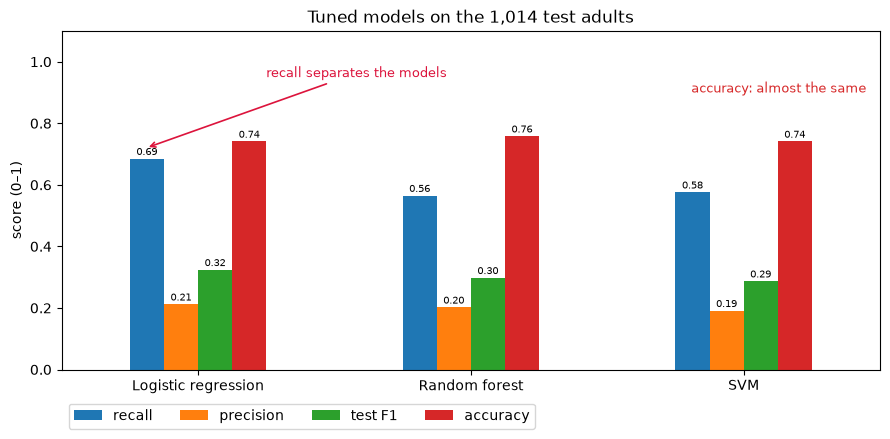

In [142]:
# the 4 scores from the Step 18 table: one group of bars per model
ax = results[['recall', 'precision', 'test F1', 'accuracy']].plot.bar(figsize=(9, 4.5), rot=0)
for bars in ax.containers:                                  # mark: the score on top of every bar
    ax.bar_label(bars, fmt='%.2f', fontsize=7, padding=1)
# mark: what to compare
ax.text(2.45, 0.9, 'accuracy: almost the same', ha='right', fontsize=9, color='tab:red')
ax.annotate('recall separates the models', xy=(-0.19, 0.72), xytext=(0.25, 0.95), arrowprops=arrow, fontsize=9, color='crimson')
plt.xlabel('')
plt.ylabel('score (0–1)')
plt.ylim(0, 1.1)
plt.legend(loc='upper left', ncol=4, bbox_to_anchor=(0, -0.08))
plt.title('Tuned models on the 1,014 test adults')
plt.tight_layout()
plt.show()

**Findings:**

- **Accuracy (red) hides the differences:** all three models score 0.74–0.76.
- **Recall (blue) separates them:** logistic regression finds 0.685 of depressed adults, against 0.565 (random forest) and 0.576 (SVM).
- **Precision is low for all three (0.19–0.21):** about 1 in 5 adults flagged is depressed. This is expected when only 9% are depressed.
- Logistic regression has the highest F1 (0.324), so the chart agrees with the Step 18 table.


**Training time per model** (recorded by GridSearchCV):

In [143]:
times = []
for name, search in searches.items():
    r, i = search.cv_results_, search.best_index_          # all results, and the row of the best setting
    times.append({'model': name,
                    'fits': len(r['params']) * 5,                              # settings x 5 folds
                    'train one model (s)': round(r['mean_fit_time'][i], 3),     # average over the 5 folds
                    'whole grid search (s)': round((r['mean_fit_time'] + r['mean_score_time']).sum() * 5, 1)})
pd.DataFrame(times).set_index('model')

,fits,train one model (s),whole grid search (s)
model,,,
Logistic regression,20,0.018,0.4
Random forest,60,0.290,19.7
SVM,45,0.190,12.0


## Step 19: What the models learned

### 19a: Logistic regression odds ratios

Each weight is turned into an odds ratio with exp(weight): above 1 = higher odds of depression, below 1 = lower. Numeric columns are per 1 SD.

In [144]:
  # numpy for e to the power of x
  import numpy as np

  # the winning model: the best logistic regression from Step 17a (already re-trained on all 4,054)
  best_lr = lr_search.best_estimator_

  # the 32 column names after prep, and the one weight learned for each
  names = best_lr.named_steps['prep'].get_feature_names_out()
  weights = best_lr.named_steps['model'].coef_[0]

  # odds ratio = e to the power of the weight
  odds = pd.DataFrame({'weight': weights, 'odds ratio': np.exp(weights)}, index=names).round(2)
  odds.index = odds.index.str.replace('num__', '').str.replace('cat__', '')   # shorter names

  # biggest increases at the top, biggest decreases at the bottom
  odds.sort_values('odds ratio', ascending=False)

,weight,odds ratio
sleep_trouble_Yes,0.65,1.92
vigorous_activity_No,0.25,1.28
told_overweight_Yes,0.24,1.27
marital_status_Widowed,0.23,1.25
smoked_100_Yes,0.14,1.15
education_Less than 9th grade,0.13,1.14
education_9–11th grade,0.11,1.12
marital_status_Divorced,0.10,1.11
heart_disease_Yes,0.10,1.10
marital_status_Separated,0.09,1.10


**Findings:**

- The table gives one odds ratio per answer column (one-hot). The meaningful comparison is one answer against the other, which the chart below works out (e.g. Yes vs No = e^(weight Yes − weight No)).
- **Sleep trouble:** sleep_trouble_Yes 1.92 and sleep_trouble_No 0.52 → Yes vs No ≈ **3.7×** the odds.
- **Income:** each 1 SD higher income gives **0.75×** the odds.
- **Married** has the lowest column odds ratio (0.67).
- These agree with the group rates in Step 11. They are associations, not causes.


### 19a (chart): Odds ratios as a chart

The one-hot weights are turned into comparisons, e.g. Yes vs No = exp(weight of Yes − weight of No). Bars right of 1 raise the odds of depression; bars left of 1 lower them.

Income, per 1 SD higher        0.75
Age, per 1 SD older            0.85
Smoked 100+: Yes vs No         1.33
Told overweight: Yes vs No     1.61
No vigorous activity vs Yes    1.64
Widowed vs Married             1.88
Trouble sleeping: Yes vs No    3.68
dtype: float64


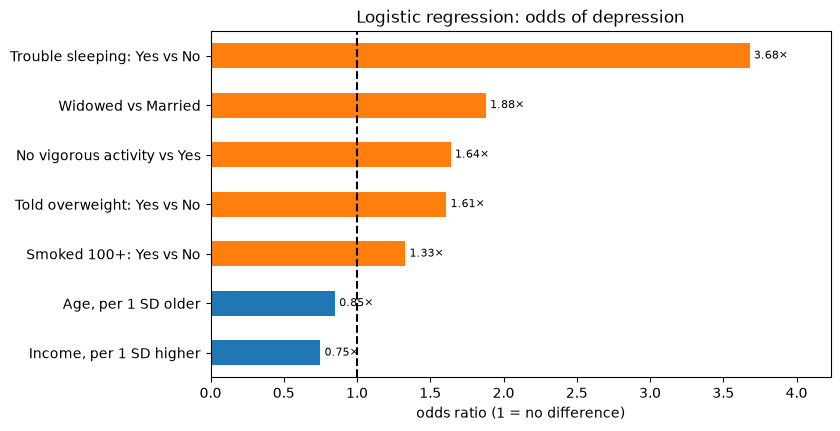

In [145]:
# the 32 unrounded weights from 19a, with the short names
w = pd.Series(weights, index=odds.index)

# odds ratio of one answer compared with another = e to the power of (weight A − weight B)
compare = pd.Series({
    'Trouble sleeping: Yes vs No': np.exp(w['sleep_trouble_Yes'] - w['sleep_trouble_No']),
    'Widowed vs Married': np.exp(w['marital_status_Widowed'] - w['marital_status_Married']),
    'No vigorous activity vs Yes': np.exp(w['vigorous_activity_No'] - w['vigorous_activity_Yes']),
    'Told overweight: Yes vs No': np.exp(w['told_overweight_Yes'] - w['told_overweight_No']),
    'Smoked 100+: Yes vs No': np.exp(w['smoked_100_Yes'] - w['smoked_100_No']),
    'Age, per 1 SD older': np.exp(w['age']),
    'Income, per 1 SD higher': np.exp(w['income_ratio'])}).round(2).sort_values()
print(compare)

# orange = raises the odds, blue = lowers them
colours = ['tab:orange' if v > 1 else 'tab:blue' for v in compare]
ax = compare.plot.barh(color=colours, figsize=(8, 4.5))
ax.bar_label(ax.containers[0], labels=[f'{v:.2f}×' for v in compare], fontsize=8, padding=3)   # mark: the value on every bar
plt.xlim(0, compare.max() * 1.15)
plt.axvline(1, color='black', ls='--')   # 1 = no difference
plt.xlabel('odds ratio (1 = no difference)')
plt.title('Logistic regression: odds of depression')
plt.show()


**Findings:**

- **Trouble sleeping: 3.68×** the odds, about twice the next factor.
- **Raise the odds:** widowed vs married 1.88×, no vigorous activity 1.64×, told overweight 1.61×, smoked 100+ 1.33×.
- **Lower the odds:** each 1 SD higher income 0.75×; each 1 SD older 0.85×. Age looked flat in Step 12f, but once income, marital status and health are held equal, older adults have slightly lower odds.
- These match Table 9 in the report. They are associations, not causes.


### 19b: Random forest feature importance

sleep_trouble_No          0.216
sleep_trouble_Yes         0.200
income_ratio              0.092
marital_status_Married    0.054
bmi                       0.054
age                       0.046
sleep_hours               0.043
sitting_minutes           0.037
vigorous_activity_No      0.027
vigorous_activity_Yes     0.027
dtype: float64


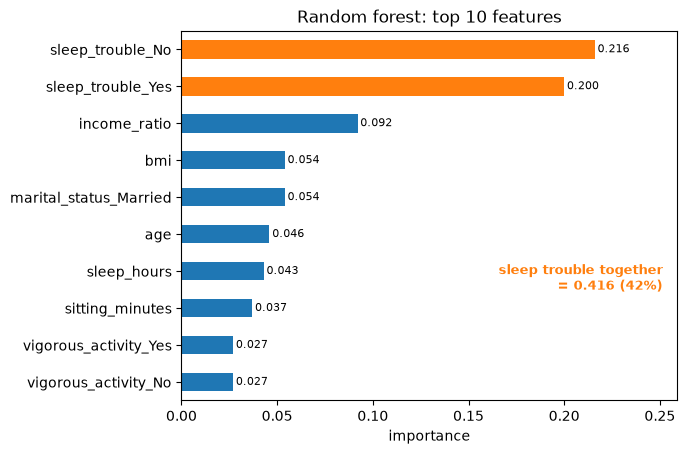

sleep_trouble        0.416
income_ratio         0.092
marital_status       0.086
bmi                  0.054
vigorous_activity    0.054
told_overweight      0.052
age                  0.046
education            0.044
sleep_hours          0.043
sitting_minutes      0.037
smoked_100           0.031
sex                  0.015
drank_past_year      0.014
cancer_ever          0.008
heart_disease        0.007
dtype: float64

In [146]:
  # the tuned random forest from Step 17b (depth 6, leaf 1), re-trained on all 4,054
  best_rf = rf_search.best_estimator_

  # one importance number per prepared column (32), shares that add up to 1
  names = best_rf.named_steps['prep'].get_feature_names_out()
  importance = pd.Series(best_rf.named_steps['model'].feature_importances_, index=names)
  importance.index = importance.index.str.replace('num__', '').str.replace('cat__', '')
  importance = importance.sort_values(ascending=False).round(3)
  print(importance.head(10))

  # Figure 9: the same top 10 as a bar chart (sort_values puts the biggest bar on top)
  top10 = importance.head(10).sort_values()
  # mark: the two sleep-trouble bars in orange, the value on every bar
  ax = top10.plot.barh(title='Random forest: top 10 features',
                       color=['tab:orange' if f.startswith('sleep_trouble') else 'tab:blue' for f in top10.index])
  ax.bar_label(ax.containers[0], fmt='%.3f', fontsize=8, padding=2)
  sleep_total = importance[importance.index.str.startswith('sleep_trouble')].sum()
  ax.text(0.97, 0.3, f'sleep trouble together\n= {sleep_total:.3f} ({sleep_total * 100:.0f}%)', transform=ax.transAxes,
          ha='right', fontsize=9, color='tab:orange', fontweight='bold')
  plt.xlim(0, top10.max() * 1.2)
  plt.xlabel('importance')
  plt.show()

  # add the one-hot columns back together: sleep_trouble_Yes + sleep_trouble_No = sleep_trouble, etc.
  features = numeric + categories                                   # the 15 original columns (Step 14)
  grouped = importance.groupby(lambda col: next(f for f in features if col == f or col.startswith(f + '_'))).sum()
  grouped.sort_values(ascending=False).round(3)

**Findings:** sleep trouble has importance 0.416 (42% of what the forest learned). The top three are sleep trouble, income and marital status, the same as the odds ratios and the Step 11 rates. Importance shows how much a feature matters, not its direction.

## Step 20: Confusion matrices and ROC curves

### 20a: Confusion matrices (rows = truth, columns = prediction)

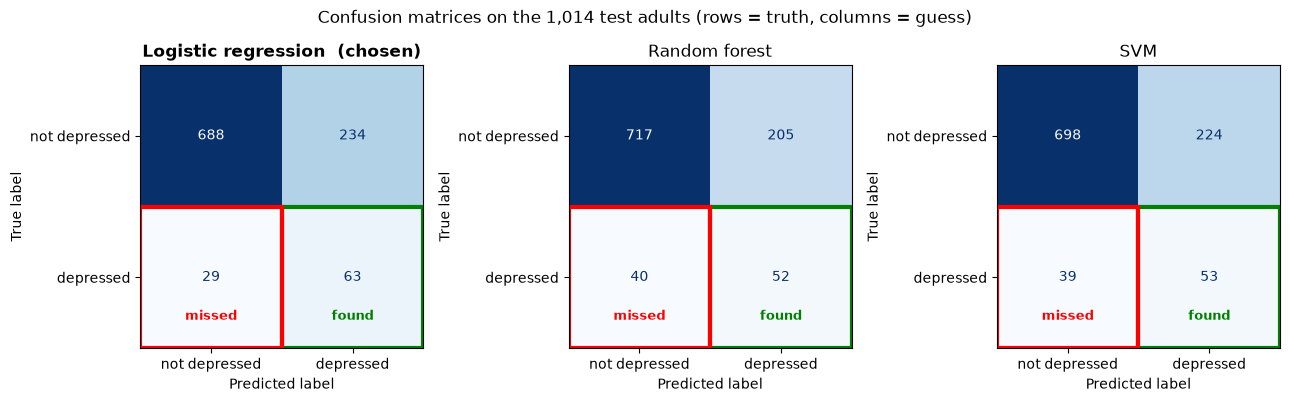

In [147]:
  # a ready-made confusion matrix chart
  from sklearn.metrics import ConfusionMatrixDisplay

  # three panels in one row, one per tuned model
  fig, axes = plt.subplots(1, 3, figsize=(13, 4))
  for ax, (name, search) in zip(axes, searches.items()):
      ConfusionMatrixDisplay.from_estimator(search, X_test, y_test, display_labels=['not depressed', 'depressed'],
                                            cmap='Blues', colorbar=False, ax=ax)
      ax.set_title(name + ('  (chosen)' if name == 'Logistic regression' else ''),
                   fontweight='bold' if name == 'Logistic regression' else 'normal')
      # marks: green box = depressed and found, red box = depressed but missed
      ax.add_patch(plt.Rectangle((0.5, 0.5), 1, 1, fill=False, edgecolor='green', lw=3))
      ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, edgecolor='red', lw=3))
      ax.text(1, 1.3, 'found', ha='center', color='green', fontsize=9, fontweight='bold')
      ax.text(0, 1.3, 'missed', ha='center', color='red', fontsize=9, fontweight='bold')
  plt.suptitle('Confusion matrices on the 1,014 test adults (rows = truth, columns = guess)')
  plt.tight_layout()
  plt.show()

**Findings:** logistic regression finds 63 of 92 depressed adults (misses 29, 234 false alarms); random forest finds 52 (misses 40, 205 false alarms); SVM finds 53 (misses 39, 224 false alarms). Logistic regression misses the fewest, at the cost of about 30 more false alarms than random forest.

### 20b: ROC curves and AUC

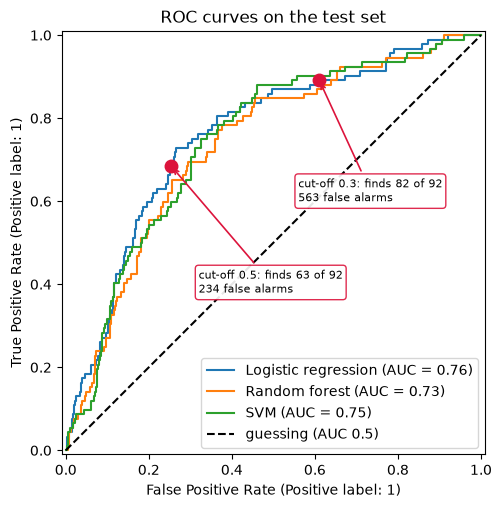

In [148]:
  # a ready-made ROC chart
  from sklearn.metrics import RocCurveDisplay

  # one curve per tuned model, all on the same axes
  fig, ax = plt.subplots(figsize=(6, 5.5))
  for name, search in searches.items():
      RocCurveDisplay.from_estimator(search, X_test, y_test, name=name, ax=ax)

  # the diagonal = guessing at random
  ax.plot([0, 1], [0, 1], 'k--', label='guessing (AUC 0.5)')
  # marks: two cut-offs as points on the logistic regression curve
  p, t = lr_search.predict_proba(X_test)[:, 1], np.asarray(y_test)
  for cut, xy_text in [(0.5, (0.32, 0.38)), (0.3, (0.56, 0.6))]:
      tp, fp = ((p >= cut) & (t == 1)).sum(), ((p >= cut) & (t == 0)).sum()
      x, y = fp / (t == 0).sum(), tp / (t == 1).sum()
      ax.plot(x, y, 'o', color='crimson', ms=9, zorder=5)
      ax.annotate(f'cut-off {cut}: finds {tp} of 92\n{fp} false alarms', xy=(x, y), xytext=xy_text,
                  arrowprops=arrow, bbox=note, fontsize=8)
  ax.set_title('ROC curves on the test set')
  ax.legend()
  plt.show()

**Findings:**

- Logistic regression has the highest AUC (**0.76**), then SVM (0.75) and random forest (0.73), agreeing with Step 18.
- All three curves are well above guessing (AUC 0.5), but far from perfect: the signal is real but moderate.
- The cut-off is a policy choice: lowering it to 30% would find 82 of the 92 depressed adults, at the cost of more follow-up checks.

### 20c: Choosing the cut-off

The model gives each adult a score from 0 to 1 and flags them if the score is at or above the cut-off (default 0.5). Here we try every cut-off from 0.10 to 0.90 and count what it finds and what it costs.

         found (of 92)  false alarms  flagged
cut-off                                      
0.3                 82           563      645
0.4                 75           376      451
0.5                 63           234      297
0.6                 45           146      191
0.7                 25            81      106


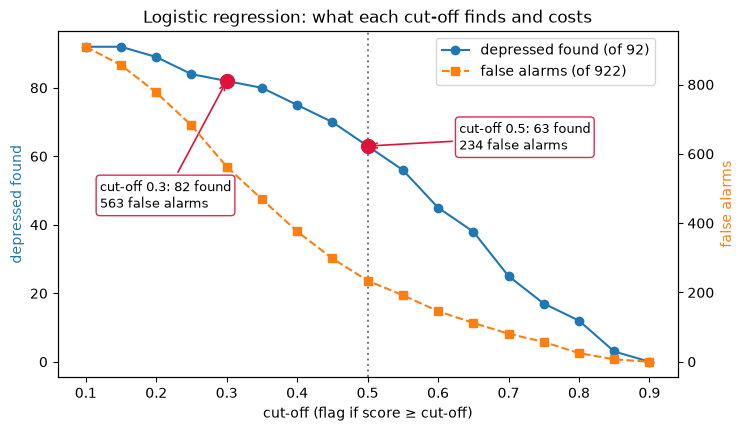

In [149]:
# the winning model's score (0–1) for each of the 1,014 test adults
score = lr_search.predict_proba(X_test)[:, 1]
truth = np.asarray(y_test)

# try cut-offs 0.10, 0.15 ... 0.90: flag everyone whose score is at or above it
rows = []
for cut in np.arange(0.10, 0.91, 0.05):
    flag = score >= cut
    rows.append({'cut-off': round(cut, 2),
                 'found (of 92)': (flag & (truth == 1)).sum(),     # depressed and flagged
                 'false alarms': (flag & (truth == 0)).sum(),      # not depressed but flagged
                 'flagged': flag.sum()})                           # everyone sent for screening
cuts = pd.DataFrame(rows).set_index('cut-off')
print(cuts.loc[[0.3, 0.4, 0.5, 0.6, 0.7]])

# two lines on one chart: found (left axis) and false alarms (right axis)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cuts.index, cuts['found (of 92)'], 'o-', color='tab:blue', label='depressed found (of 92)')
ax.set_xlabel('cut-off (flag if score ≥ cut-off)')
ax.set_ylabel('depressed found', color='tab:blue')

ax2 = ax.twinx()                       # a second y axis on the right
ax2.plot(cuts.index, cuts['false alarms'], 's--', color='tab:orange', label='false alarms (of 922)')
ax2.set_ylabel('false alarms', color='tab:orange')

ax.axvline(0.5, color='grey', ls=':')  # the default cut-off used in Step 18

# marks: what the 0.5 and 0.3 cut-offs find and cost
for cut, xy_text in [(0.3, (0.12, 45)), (0.5, (0.63, 62))]:
    found, fa = cuts.loc[cut, 'found (of 92)'], cuts.loc[cut, 'false alarms']
    ax.plot(cut, found, 'o', color='crimson', ms=10, zorder=5)
    ax.annotate(f'cut-off {cut}: {found} found\n{fa} false alarms', xy=(cut, found), xytext=xy_text,
                arrowprops=arrow, bbox=note, fontsize=9)
fig.legend(loc='upper right', bbox_to_anchor=(0.88, 0.88))
plt.title('Logistic regression: what each cut-off finds and costs')
plt.show()


**Findings:**

| Cut-off | Found (of 92) | False alarms | Flagged (of 1,014) |
|---|---|---|---|
| 0.3 | 82 (89%) | 563 | 645 (64%) |
| 0.4 | 75 (82%) | 376 | 451 (44%) |
| **0.5 (used)** | **63 (68%)** | **234** | **297 (29%)** |
| 0.6 | 45 (49%) | 146 | 191 (19%) |
| 0.7 | 25 (27%) | 81 | 106 (10%) |

- Lowering the cut-off finds more depressed adults but flags many more who are not. Going from 0.5 to 0.3 finds 19 more depressed adults at the cost of 329 more false alarms: about **17 extra follow-ups for each extra person found**.
- The right cut-off is a policy choice: it depends on how many PHQ-9 follow-ups a clinic can offer. A false alarm costs only a short questionnaire, so a cut-off of 0.4–0.5 is reasonable for screening.


# Part E: Unsupervised learning

## Step 21: k-means clustering

k-means groups adults on the 5 numeric columns without seeing `depressed`. Afterwards we check each group's depression rate.

### 21a: Prepare the numeric columns

Gaps are filled with the median and each column is min-max scaled to 0–1, so no unit (e.g. sitting minutes, 0–1,320) dominates the distances.

In [150]:
  # the 5 amount columns from Step 7 (no Yes/No answers, no outcome)
  C = df[numeric]

  # 1. fill gaps with each column's median
  C = C.fillna(C.median())

  # 2. min-max scale every column to 0–1
  C_scaled = (C - C.min()) / (C.max() - C.min())

  print('gaps left:', C.isna().sum().sum())
  C_scaled.describe().round(2)

gaps left: 0


,age,income_ratio,sleep_hours,bmi,sitting_minutes
count,5068.00,5068.00,5068.00,5068.00,5068.00
mean,0.51,0.50,0.47,0.21,0.25
std,0.30,0.30,0.14,0.10,0.15
min,0.00,0.00,0.00,0.00,0.00
25%,0.24,0.26,0.38,0.14,0.14
50%,0.53,0.43,0.46,0.19,0.23
75%,0.74,0.74,0.54,0.26,0.36
max,1.00,1.00,1.00,1.00,1.00


### 21b: Elbow method (choose k)

WSS (within-cluster sum of squares) for k = 1 to 8. The chosen k is the first one where one more group lowers WSS by less than 15%.

In [151]:
from sklearn.cluster import KMeans

k=1: WSS 1178.4 -> one more group lowers it by 30.8%
k=2: WSS 815.0 -> one more group lowers it by 32.1%
k=3: WSS 553.7 -> one more group lowers it by 13.9%
k=4: WSS 477.0 -> one more group lowers it by 9.2%
k=5: WSS 433.2 -> one more group lowers it by 6.4%
k=6: WSS 405.2 -> one more group lowers it by 6.4%
k=7: WSS 379.5 -> one more group lowers it by 5.6%


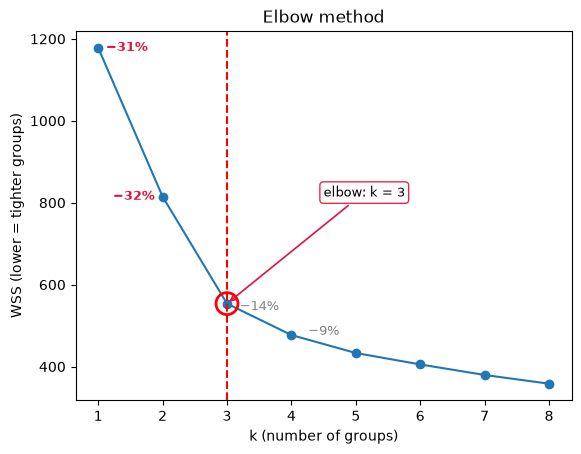

In [152]:
# WSS (inertia) for 1 to 8 groups
wss = {}
for k in range(1, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=0)
    km.fit(C_scaled)
    wss[k] = km.inertia_

# how much each extra group lowers WSS
for k in range(1, 8):
    drop = (wss[k] - wss[k + 1]) / wss[k] * 100
    print(f'k={k}: WSS {wss[k]:.1f} -> one more group lowers it by {drop:.1f}%')

# the elbow chart
plt.plot(list(wss.keys()), list(wss.values()), 'o-')
plt.axvline(3, color='red', ls='--')

# marks: the % drop on each step (red = big drops before the elbow), and a ring on k = 3
for k in range(1, 5):
    drop = (wss[k] - wss[k + 1]) / wss[k] * 100
    # k=1: right of the point; k=2: left of the point; k=3, 4: above the line
    x, y, ha, va = {1: (k + 0.12, wss[k], 'left', 'center'), 2: (k - 0.12, wss[k], 'right', 'center')}.get(
        k, (k + 0.5, (wss[k] + wss[k + 1]) / 2 + 15, 'center', 'bottom'))
    plt.text(x, y, f'−{drop:.0f}%', fontsize=9, ha=ha, va=va,
             color='crimson' if k < 3 else 'gray', fontweight='bold' if k < 3 else 'normal')
plt.scatter([3], [wss[3]], s=250, facecolors='none', edgecolors='red', lw=2, zorder=3)
plt.annotate('elbow: k = 3', xy=(3, wss[3]), xytext=(4.5, wss[2]), arrowprops=arrow, bbox=note, fontsize=9)

plt.xlabel('k (number of groups)')
plt.ylabel('WSS (lower = tighter groups)')
plt.title('Elbow method')
plt.show()

**Result:** WSS drops by 31% and 32% up to k = 3, then by only 14%, 9% and 6%, so **k = 3**.

### 21c: The 3 groups and their depression rates

overall depression rate: 9.1 %


,age,income_ratio,sleep_hours,bmi,sitting_minutes,depressed,people
cluster,,,,,,,
1,65.26,1.65,7.68,30.17,317.94,11.9,1898
0,31.40,1.51,7.68,29.85,309.79,9.6,1750
2,50.98,4.60,7.38,29.18,378.90,4.6,1420


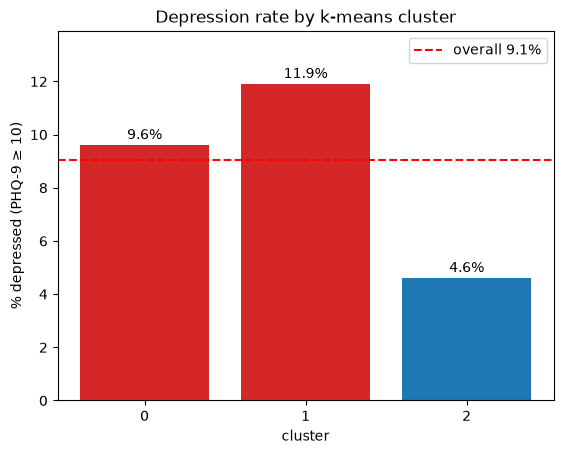

In [153]:
  # 1. make the 3 groups and label every person
  km = KMeans(n_clusters=3, n_init=20, random_state=0)
  df['cluster'] = km.fit_predict(C_scaled)

  # 2. profile: average of each number + depression rate, per group
  profile = df.groupby('cluster')[numeric + ['depressed']].mean()
  profile['depressed'] = (profile['depressed'] * 100).round(1)  # share -> %, rounded once (0.0960 -> 9.6, not 0.10 -> 10.0)
  profile[numeric] = profile[numeric].round(2)
  profile['people'] = df['cluster'].value_counts().sort_index()
  print('overall depression rate:', round(df['depressed'].mean() * 100, 1), '%')
  display(profile.sort_values('depressed', ascending=False))

  # 3. one bar per group: its depression rate
  bars = plt.bar(profile.index.astype(str), profile['depressed'],
                 color=['tab:red' if v > df['depressed'].mean() * 100 else 'tab:blue' for v in profile['depressed']])
  plt.bar_label(bars, fmt='%.1f%%', padding=2)           # mark: the rate on every bar
  plt.ylim(0, profile['depressed'].max() + 2)
  plt.axhline(df['depressed'].mean() * 100, color='red', ls='--', label='overall 9.1%')
  plt.xlabel('cluster')
  plt.ylabel('% depressed (PHQ-9 ≥ 10)')
  plt.title('Depression rate by k-means cluster')
  plt.legend()
  plt.show()

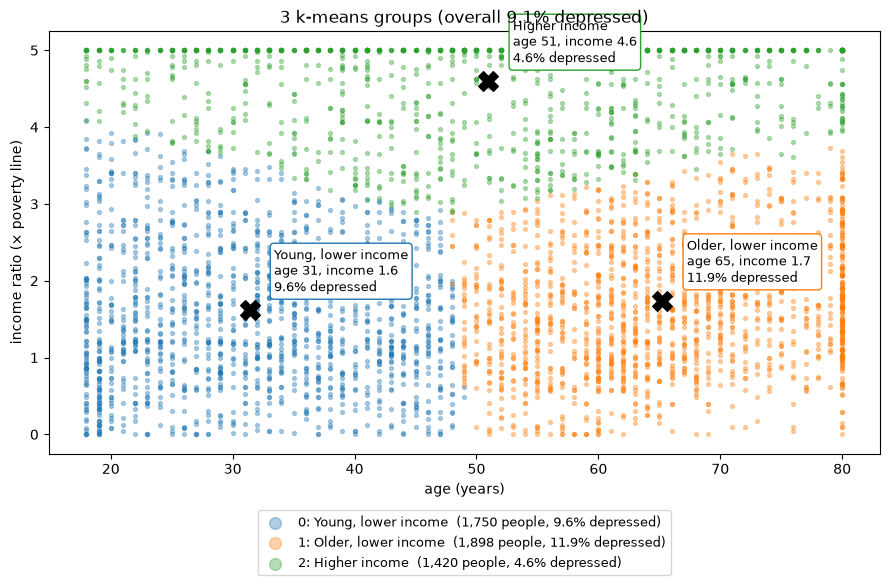

In [154]:
  # readable names (from the profile table)
  names = {0: 'Young, lower income', 1: 'Older, lower income', 2: 'Higher income'}
  colours = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:green'}

  # group centres, turned back from 0–1 into real units
  centres = pd.DataFrame(km.cluster_centers_, columns=numeric)
  centres = centres * (C.max() - C.min()) + C.min()

  plt.figure(figsize=(9, 6))
  for c in [0, 1, 2]:
      group = df[df['cluster'] == c]
      rate = profile.loc[c, 'depressed']
      plt.scatter(group['age'], group['income_ratio'], s=8, alpha=0.35, color=colours[c],
                  label=f'{c}: {names[c]}  ({len(group):,} people, {rate}% depressed)')

      # label box at the group's centre
      x, y = centres.loc[c, 'age'], centres.loc[c, 'income_ratio']
      plt.scatter(x, y, color='black', marker='X', s=200)
      plt.annotate(f'{names[c]}\nage {x:.0f}, income {y:.1f}\n{rate}% depressed',
                   xy=(x, y), xytext=(x + 2, y + 0.25), fontsize=9,
                   bbox=dict(boxstyle='round', facecolor='white', edgecolor=colours[c]))

  plt.xlabel('age (years)')
  plt.ylabel('income ratio (× poverty line)')
  plt.title(f'3 k-means groups (overall {df["depressed"].mean() * 100:.1f}% depressed)')
  plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), markerscale=3, fontsize=9)
  plt.tight_layout()
  plt.show()

**Findings:**

| Group | Age | Income ratio | Depressed | Adults |
|---|---|---|---|---|
| Older, lower income | 65 | 1.65 | **11.9%** | 1,898 |
| Young, lower income | 31 | 1.51 | **9.6%** | 1,750 |
| Higher income | 51 | 4.60 | **4.6%** | 1,420 |

Without seeing who is depressed, k-means separated adults mainly by **income** and **age**. The higher-income group has less than half the depression rate of the two lower-income groups (older lower income is 2.6× higher), agreeing with Steps 12d and 19a. Sleep and BMI barely differ between groups.

### 21d: What makes each group different?

The 3 group centres in 0–1 units (21a scaling), one bar per column. Columns where the bars differ a lot are the ones that shaped the groups.

                      age  income_ratio  sleep_hours   bmi  sitting_minutes
Young, lower income  0.22          0.32         0.47  0.21             0.23
Older, lower income  0.76          0.35         0.47  0.21             0.24
Higher income        0.53          0.92         0.45  0.20             0.29


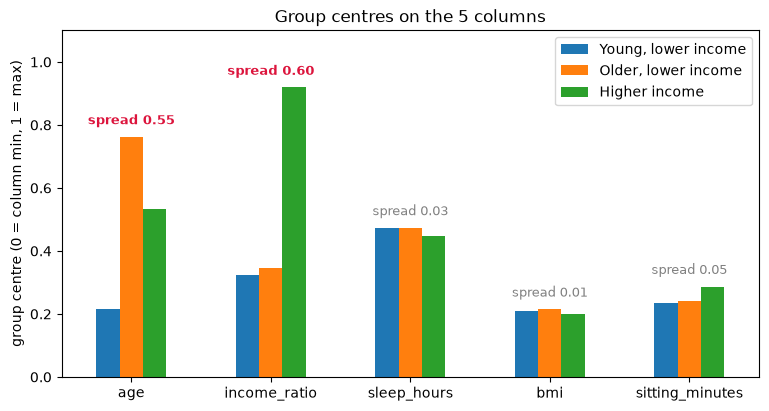

income_ratio       0.60
age                0.55
sitting_minutes    0.05
sleep_hours        0.03
bmi                0.01
dtype: float64


In [155]:
# group centres in 0–1 units, one row per group, readable names
centres01 = pd.DataFrame(km.cluster_centers_, columns=numeric, index=[names[c] for c in range(3)])
print(centres01.round(2))

# one group of bars per column, one colour per group (same colours as 21c)
ax = centres01.T.plot.bar(figsize=(9, 4.5), rot=0, color=[colours[c] for c in range(3)])

# mark: the spread of the 3 centres above each column (red = this column separates the groups)
for i, col in enumerate(numeric):
    spread = centres01[col].max() - centres01[col].min()
    ax.text(i, centres01[col].max() + 0.04, f'spread {spread:.2f}', ha='center', fontsize=9,
            color='crimson' if spread > 0.3 else 'gray', fontweight='bold' if spread > 0.3 else 'normal')
plt.ylim(0, 1.1)
plt.ylabel('group centre (0 = column min, 1 = max)')
plt.title('Group centres on the 5 columns')
plt.show()

# spread of the 3 centres per column: big = this column separates the groups
print((centres01.max() - centres01.min()).round(2).sort_values(ascending=False))


**Findings:**

- **Income** (spread 0.60) and **age** (0.55) separate the groups.
- Sleep hours (0.03), BMI (0.01) and sitting (0.05) are almost the same in all three groups.
- So the clusters are really **age × income groups**: young lower income, older lower income, and higher income at any age.


### 21e: Sleep trouble inside each group

k-means could only use the 5 numbers, so it never saw sleep trouble, the strongest factor from Steps 11 and 19. Here we split each group by sleep trouble.

sleep_trouble         No   Yes
cluster                       
Higher income        1.8  12.1
Older, lower income  5.9  23.2
Young, lower income  5.5  24.8


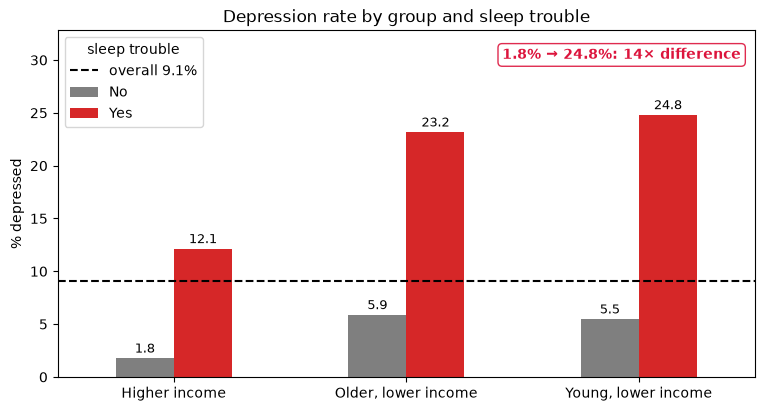

In [156]:
# % depressed for each group x sleep-trouble answer
inside = df.groupby([df['cluster'].map(names), 'sleep_trouble'])['depressed'].mean().unstack() * 100
print(inside.round(1))

ax = inside.plot.bar(figsize=(9, 4.5), rot=0, color=['tab:gray', 'tab:red'])
for bars in ax.containers:                                  # mark: the rate on every bar
    ax.bar_label(bars, fmt='%.1f', fontsize=9, padding=2)
plt.axhline(df['depressed'].mean() * 100, color='black', ls='--', label='overall 9.1%')

# mark: lowest vs highest
lo, hi = inside['No'].min(), inside['Yes'].max()
ax.text(0.98, 0.95, f'{lo:.1f}% → {hi:.1f}%: {hi / lo:.0f}× difference', transform=ax.transAxes,
        ha='right', va='top', fontsize=10, color='crimson', fontweight='bold', bbox=note)
plt.ylim(0, hi + 8)
plt.ylabel('% depressed')
plt.xlabel('')
plt.legend(title='sleep trouble', loc='upper left')
plt.title('Depression rate by group and sleep trouble')
plt.show()

**Findings:**

| Group | No sleep trouble | Sleep trouble |
|---|---|---|
| Higher income | **1.8%** | 12.1% |
| Older, lower income | 5.9% | 23.2% |
| Young, lower income | 5.5% | **24.8%** |

- Sleep trouble raises the depression rate in **every** group, about 4–7×.
- Income and sleep trouble add together. Lower income with sleep trouble means about **1 in 4** adults are depressed. Higher income without sleep trouble means about **1 in 55**. That is a 14× difference.
- This is what k-means could not see on its own, and why the supervised models (which do use sleep trouble) do better.


### 21f: Are the groups stable?

Run k-means again with 5 different random starts and compare each result with the 21c groups. The adjusted Rand index is 1 when two groupings are identical (whatever the labels are called) and about 0 when they match only by chance.

In [157]:
# agreement between two groupings, from scikit-learn
from sklearn.metrics import adjusted_rand_score

for seed in [1, 2, 3, 4, 5]:
    again = KMeans(n_clusters=3, n_init=20, random_state=seed).fit_predict(C_scaled)
    print(f'random_state={seed}: adjusted Rand index {adjusted_rand_score(df["cluster"], again):.3f}')


random_state=1: adjusted Rand index 0.998
random_state=2: adjusted Rand index 1.000
random_state=3: adjusted Rand index 0.999
random_state=4: adjusted Rand index 1.000
random_state=5: adjusted Rand index 0.999


**Findings:** the adjusted Rand index is **0.998–1.000** for all 5 new random starts, so k-means finds the same 3 groups every time. The groups are stable, not a lucky result of one random start.

### 21g: The 3 groups in 3D (PCA with 3 axes)

The 21c scatter used only age and income. PCA squeezes all 5 scaled columns into 3 new axes that keep as much of the spread as possible, so we can see the groups using every column, in 3D, as in the NHANES clustering example by Bryan O. (RPubs, 2022), who plotted PC1, PC2 and PC3 coloured by cluster.

spread kept by PC1, PC2, PC3: [0.42 0.36 0.1 ] | together: 0.88
      age  income_ratio  sleep_hours   bmi  sitting_minutes
PC1  0.61          0.79        -0.03 -0.00             0.08
PC2  0.80         -0.60         0.03  0.02            -0.06
PC3 -0.00         -0.09        -0.08  0.16             0.98


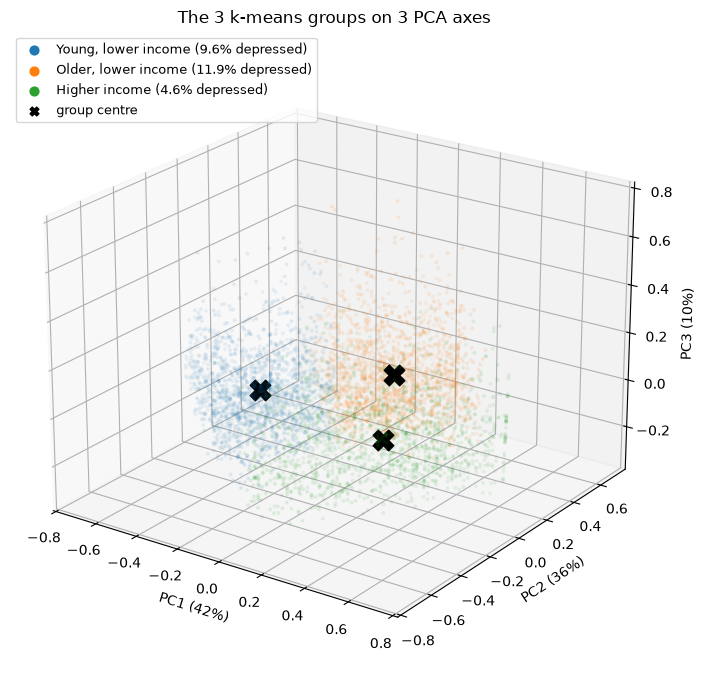

In [158]:
# principal component analysis from scikit-learn, and 3D axes for matplotlib (registers projection='3d')
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D

# 3 PCA axes from the 5 scaled columns of 21a
pca3 = PCA(n_components=3, random_state=0)
xyz3 = pca3.fit_transform(C_scaled)
share = pca3.explained_variance_ratio_
print('spread kept by PC1, PC2, PC3:', share.round(2), '| together:', round(share.sum(), 2))

# which columns build each axis (bigger number = bigger part)
print(pd.DataFrame(pca3.components_, columns=numeric, index=['PC1', 'PC2', 'PC3']).round(2))

# the 3 group centres from 21c, moved into the same PCA space
cent = pca3.transform(pd.DataFrame(km.cluster_centers_, columns=numeric))

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection='3d')
for c in range(3):
    pts = xyz3[df['cluster'] == c]
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=4, alpha=0.3, color=colours[c],
               label=f"{names[c]} ({profile.loc[c, 'depressed']}% depressed)")
# mark: a black X on every group centre
ax.scatter(cent[:, 0], cent[:, 1], cent[:, 2], color='black', marker='X', s=220, depthshade=False, label='group centre')
ax.set_xlabel(f'PC1 ({share[0] * 100:.0f}%)')
ax.set_ylabel(f'PC2 ({share[1] * 100:.0f}%)')
ax.set_zlabel(f'PC3 ({share[2] * 100:.0f}%)')
ax.view_init(elev=22, azim=-55)          # camera angle: 22° up, turned 55°
leg = ax.legend(loc='upper left', fontsize=9)
for h in leg.legend_handles:              # same-size, solid dots in the legend
    h.set_sizes([40]); h.set_alpha(1)
plt.title('The 3 k-means groups on 3 PCA axes')
plt.tight_layout()
plt.show()

**Findings:**

- The 3 PCA axes keep **88%** of the spread in the 5 columns (42% + 36% + 10%).
- PC1 and PC2 are built almost only from age and income (PC1: income 0.79, age 0.61; PC2: age 0.80, income −0.60). PC3 is almost only sitting time (0.98). Sleep and BMI add almost nothing, which confirms 21d.
- In 3D the groups are 3 separate clouds with their centres (black X) well apart. The straight lines of dots are the adults recorded at the caps: age 80 and income ratio 5.


### 21h: PHQ-9 scores inside each group (box plot)

21c compared the share of each group above the cut-off. The box plot shows the whole spread of PHQ-9 scores in each group.

                      count  mean   std  min  25%  50%  75%   max
cluster                                                          
Higher income        1420.0  2.26  3.23  0.0  0.0  1.0  3.0  22.0
Young, lower income  1750.0  3.52  4.37  0.0  0.0  2.0  5.0  25.0
Older, lower income  1898.0  3.72  4.66  0.0  0.0  2.0  6.0  25.0


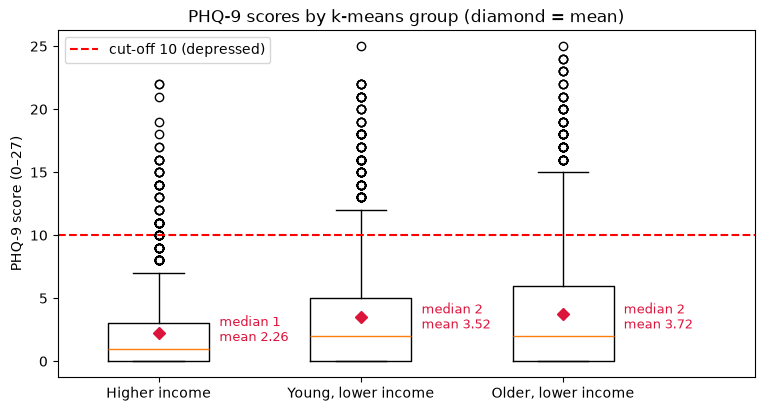

In [159]:
order3 = ['Higher income', 'Young, lower income', 'Older, lower income']   # lowest to highest depression rate

scores = [df.loc[df['cluster'].map(names) == g, 'phq9_score'] for g in order3]
print(df.groupby(df['cluster'].map(names))['phq9_score'].describe().loc[order3].round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(scores, widths=0.5)
ax.set_xticks(range(1, 4), order3)
ax.axhline(10, color='red', ls='--', label='cut-off 10 (depressed)')
# marks: a diamond on every mean, and the median and mean written beside the box
for x, s in enumerate(scores, start=1):
    ax.plot(x, s.mean(), 'D', color='crimson')
    ax.text(x + 0.3, s.median() + 0.6, f'median {s.median():g}\nmean {s.mean():.2f}', fontsize=9, color='crimson')
ax.set_xlim(0.5, 3.95)
ax.set_ylabel('PHQ-9 score (0–27)')
ax.legend(loc='upper left')
plt.title('PHQ-9 scores by k-means group (diamond = mean)')
plt.show()

**Findings:** all three groups have a low median (1–2), because about three quarters of adults score 0–4. The difference is in the upper tail. The box (middle 50%) reaches 3 in the higher-income group but 5–6 in the two lower-income groups, and the means are 2.26, 3.52 and 3.72. So k-means separated adults with lower scores across the whole range, not only at the cut-off of 10.

### 21i: Severity bands inside each group

The standard PHQ-9 bands (Kroenke et al., 2001): none 0–4, mild 5–9, moderate 10–14, moderately severe 15–19, severe 20–27. Each bar is one group split into the 5 bands (adds to 100%).

phq9_score           None (0–4)  Mild (5–9)  Moderate (10–14)  \
cluster                                                         
Higher income              83.5        11.8               3.5   
Young, lower income        72.7        17.7               5.7   
Older, lower income        69.2        18.9               7.6   
All adults                 74.4        16.5               5.8   

phq9_score           Mod. severe (15–19)  Severe (20–27)  
cluster                                                   
Higher income                        1.0             0.2  
Young, lower income                  3.0             1.0  
Older, lower income                  3.1             1.2  
All adults                           2.4             0.8  


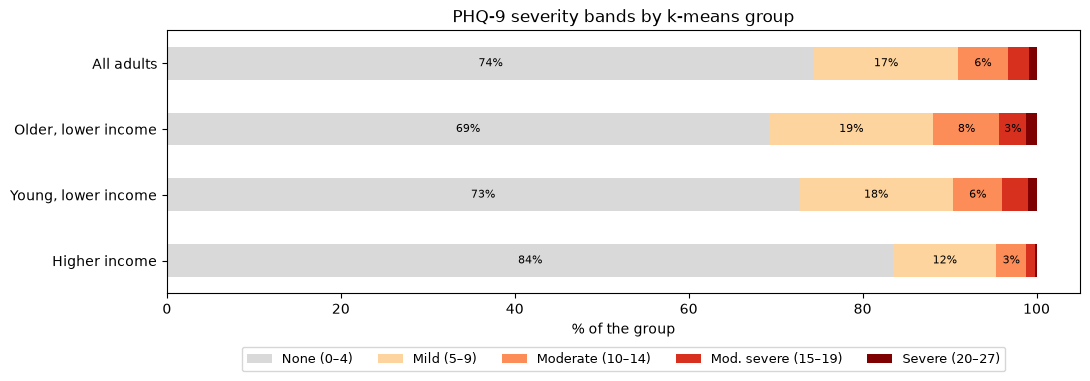

In [160]:
order3 = ['Higher income', 'Young, lower income', 'Older, lower income']   # lowest to highest depression rate

bands = pd.cut(df['phq9_score'], bins=[-1, 4, 9, 14, 19, 27],
               labels=['None (0–4)', 'Mild (5–9)', 'Moderate (10–14)', 'Mod. severe (15–19)', 'Severe (20–27)'])
sev = pd.crosstab(df['cluster'].map(names), bands, normalize='index') * 100
sev.loc['All adults'] = bands.value_counts(normalize=True).reindex(sev.columns) * 100
sev = sev.loc[order3 + ['All adults']]
print(sev.round(1))

ax = sev.plot.barh(stacked=True, figsize=(11, 4), color=['#d9d9d9', '#fdd49e', '#fc8d59', '#d7301f', '#7f0000'])
for bars in ax.containers:                         # mark: the % inside every band wide enough to read
    ax.bar_label(bars, labels=[f'{v:.0f}%' if v >= 3 else '' for v in bars.datavalues], label_type='center', fontsize=8)
ax.set_xlabel('% of the group')
ax.set_ylabel('')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=5, fontsize=9)
plt.title('PHQ-9 severity bands by k-means group')
plt.tight_layout()
plt.show()

**Findings:**

| Group | None (0–4) | Mild (5–9) | Moderate (10–14) | Mod. severe (15–19) | Severe (20–27) |
|---|---|---|---|---|---|
| Higher income | **83.5%** | 11.8% | 3.5% | 1.0% | 0.2% |
| Young, lower income | 72.7% | 17.7% | 5.7% | 3.0% | 1.0% |
| Older, lower income | 69.2% | 18.9% | **7.6%** | 3.1% | 1.2% |
| All adults | 74.4% | 16.5% | 5.8% | 2.4% | 0.8% |

- Every band above "none" is smaller in the higher-income group: it has about 6× fewer severe cases than the older lower-income group (0.2% vs 1.2%).
- The **mild** band (5–9) holds 12–19% of each group. These adults sit just below the cut-off of 10.

**Summary of Part E:** the elbow method chooses 3 groups, which are stable (Rand index ≈ 1) and differ in depression rate (11.9%, 9.6% and 4.6%). They are shaped by age and income only. Sleep trouble, which k-means could not use, raises the rate inside every group, so the highest-risk adults are lower-income adults with sleep trouble (about 25% depressed). The 3D PCA view, the PHQ-9 box plots and the severity bands (21g–21i) show the same order of risk across the whole score range, not only at the cut-off.